In [1]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import svm
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    auc,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.multiclass import OneVsRestClassifier
from toolbox import (
    Masking,
    combined_frequency_roc_analysis,
    compute_ROC_patient_split,
    find_all_indices,
    get_freqs,
    hot_coding,
)
from toolbox.loading import load_data
from toolbox.visualization import cmap_gradient, color_palette_full

In [2]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

# set prints off
mask.prints = False

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"MC"`

In [4]:
class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

In [5]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]


elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "Mild dysplasia", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_MC[select_idx]

Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
Y, inverse_mapping = hot_coding(labels)
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)

Healthy vs. cancer

Healthy: 89 entries
Cancer: 91 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Healthy'): [0, 1]}

Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(180, 31, 7728) (180, 2) (180,)


## Analysis stage: Frequency selection **and** IIVV selection

In [6]:
# load masking selection
Mask_sel = {
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Close skip 1": "vv_distance_close_skip_1",
    "All": "all",
}

In [7]:
# load frequency selection results from `frequency-analysis.ipynb`
tmp = np.load("results/freq_fold_results.npz", allow_pickle=True)
top_freqs_baseline = tmp["top_freqs_baseline"]
top_2 = top_freqs_baseline[:2]
top_3 = top_freqs_baseline[:3]
top_5 = top_freqs_baseline[:5]
top_12 = top_freqs_baseline[:12]

Freq_sel = {
    "Top 2": top_2,
    "Top 3": top_3,
    "Top 5": top_5,
    "Top 12": top_12,
    "All": top_freqs_baseline,  # np.arange(31), # it doesn't matter
}

In [8]:
Freq_sel

{'Top 2': array([30,  0]),
 'Top 3': array([30,  0, 27]),
 'Top 5': array([30,  0, 27, 12, 29]),
 'Top 12': array([30,  0, 27, 12, 29, 28, 13, 16, 20,  8, 26, 23]),
 'All': array([30,  0, 27, 12, 29, 28, 13, 16, 20,  8, 26, 23, 11, 24, 25, 15, 10,
        17, 22,  1, 21, 19, 14,  2,  7, 18,  3,  4,  5,  9,  6])}

In [9]:
Mask_sel

{'Long a+': 'vv_long_across',
 'Long a+ ext.': 'vv_long_across_extended',
 'Med. a+ ext.': 'vv_medium_across_extended',
 'Close skip 1': 'vv_distance_close_skip_1',
 'All': 'all'}

In [10]:
# setup folds
n_folds = 5
random_state = 0


unique_patients = np.unique(Case)
np.random.seed(random_state)

# Check if Y is in one-hot encoding
if len(Y.shape) == 1 or Y.shape[1] == 1:
    raise ValueError("Labels (Y) must be in one-hot encoding format")
n_classes = Y.shape[1]

patient_indices = np.arange(len(unique_patients))
np.random.shuffle(patient_indices)

# Split these indices into n_folds
fold_size = len(patient_indices) // n_folds
folds = []

for i in range(n_folds):
    if i == n_folds - 1:
        # Last fold gets all remaining patients
        test_indices = patient_indices[i * fold_size :]
    else:
        test_indices = patient_indices[i * fold_size : (i + 1) * fold_size]
    # Training indices are all other indices
    train_indices = np.setdiff1d(patient_indices, test_indices)
    folds.append((train_indices, test_indices))

In [11]:
def foldstats(train_mask, test_mask):
    # Verify split
    train_pct = train_mask.mean() * 100
    test_pct = test_mask.mean() * 100
    print(f"\nFold {fold}: {train_pct:.1f}% train / {test_pct:.1f}% test")

    # Count samples and patients in each set
    train_samples = np.sum(train_mask)
    test_samples = np.sum(test_mask)
    train_patient_count = len(train_patients)
    test_patient_count = len(test_patients)

    print(f"Fold {fold}: {train_pct:.1f}% train / {test_pct:.1f}% test")
    print(f"  Training: {train_samples} samples from {train_patient_count} patients")
    print(f"  Testing:  {test_samples} samples from {test_patient_count} patients")


def ROC_AUC_for_class(Y_test, y_score, n_classes):
    # Compute ROC AUC for each class
    roc_auc_scores = []
    for i in range(n_classes):
        score = roc_auc_score(Y_test[:, i], y_score[:, i])
        roc_auc_scores.append(score)
    # Calculate average AUC across classes
    avg_auc = np.mean(roc_auc_scores) if roc_auc_scores else 0
    return avg_auc


def ConfusionMatrix_Stats(y_pred, Y_test, inverse_mapping):

    y_test_tuples = [tuple(row) for row in Y_test.astype(int)]
    y_pred_tuples = [tuple(row) for row in y_pred.astype(int)]
    # inverse mapping
    y_test_labels = [inverse_mapping[t] for t in y_test_tuples]
    y_pred_labels = [inverse_mapping[t] for t in y_pred_tuples]
    class_labels = list(inverse_mapping.values())
    # confusion matrix
    cm = confusion_matrix(y_test_labels, y_pred_labels, labels=class_labels)
    print("Confusion Matrix:\n", cm)
    # Binary Case
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        print(f"True Positives: {tp}")
        print(f"False Positives: {fp}")
        print(f"True Negatives: {tn}")
        print(f"False Negatives: {fn}")

    # Multi-Class Case
    else:
        print("Rates not implemented for multiclass")
        # metrics_list = []
        # for i, class_name in enumerate(class_labels):
        #    tp = cm[i, i]
        #    fp = cm[:, i].sum() - tp
        #    fn = cm[i, :].sum() - tp
        #    tn = cm.sum() - (tp + fp + fn)
        #    metrics_list.append(
        #        {"Class": class_name, "TP": tp, "FP": fp, "FN": fn, "TN": tn}
        #    )
        # metrics_df = pd.DataFrame(metrics_list)
        # print("\nTP / FP / FN / TN per class:\n")
        # print(metrics_df)

    # Classification Report
    print("\nClassification Report:\n")
    print(
        classification_report(y_test_labels, y_pred_labels, target_names=class_labels)
    )

    # Plot
    fig, ax = plt.subplots(figsize=(6, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    disp.plot(cmap=cmap_gradient, ax=ax)
    plt.title("Confusion Matrix")
    plt.show()

Train patients: [ 0  1  3  4  6  7 10 11 12 13 15 16 19 20 21 22 23 25 27 28 29 30 31 32
 34 35 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 55 56 57 58 60
 61 62 66 67 68 69 70 72 73 74 75 76 77 78 79 81 84 85 86 87 88 89 90 91
 92 95 96 97]
Test patients: [ 2 33 59 18 14 64 65 83 36 82 80  8 54 94 99 63  9 24]

Fold 1: 77.2% train / 22.8% test
Fold 1: 77.2% train / 22.8% test
  Training: 139 samples from 76 patients
  Testing:  41 samples from 18 patients
Top 2 Long a+
Confusion Matrix:
 [[14  8]
 [ 5 14]]
True Positives: 14
False Positives: 8
True Negatives: 14
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.74      0.64      0.68        22
     Healthy       0.64      0.74      0.68        19

    accuracy                           0.68        41
   macro avg       0.69      0.69      0.68        41
weighted avg       0.69      0.68      0.68        41



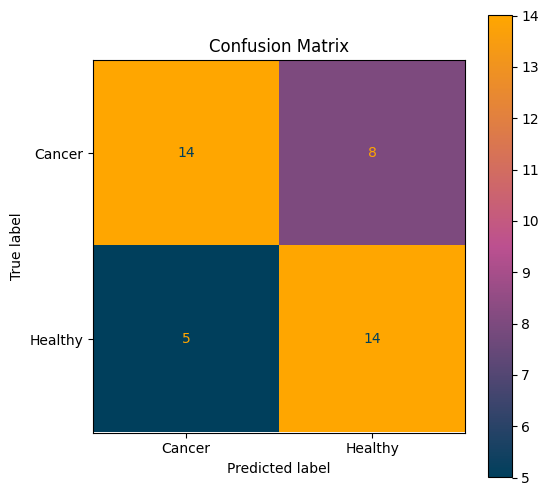

Top 3 Long a+
Confusion Matrix:
 [[15  7]
 [ 6 13]]
True Positives: 13
False Positives: 7
True Negatives: 15
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.71      0.68      0.70        22
     Healthy       0.65      0.68      0.67        19

    accuracy                           0.68        41
   macro avg       0.68      0.68      0.68        41
weighted avg       0.68      0.68      0.68        41



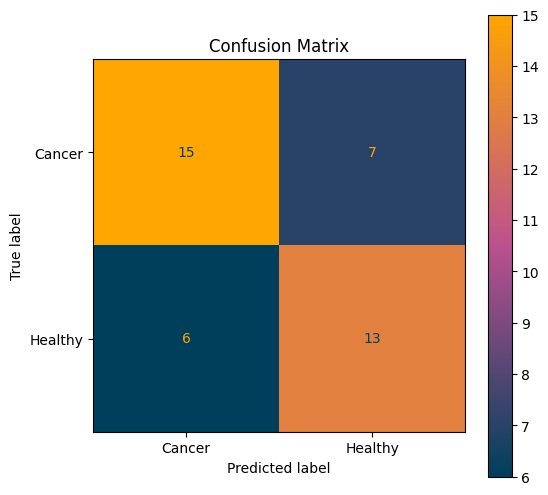

Top 5 Long a+
Confusion Matrix:
 [[14  8]
 [ 6 13]]
True Positives: 13
False Positives: 8
True Negatives: 14
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.70      0.64      0.67        22
     Healthy       0.62      0.68      0.65        19

    accuracy                           0.66        41
   macro avg       0.66      0.66      0.66        41
weighted avg       0.66      0.66      0.66        41



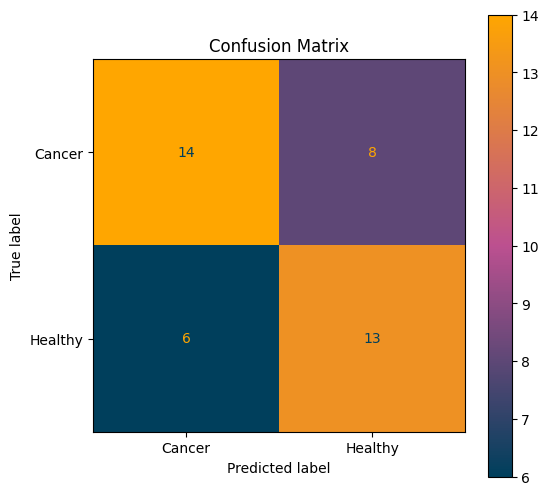

Top 12 Long a+
Confusion Matrix:
 [[13  9]
 [ 7 12]]
True Positives: 12
False Positives: 9
True Negatives: 13
False Negatives: 7

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.65      0.59      0.62        22
     Healthy       0.57      0.63      0.60        19

    accuracy                           0.61        41
   macro avg       0.61      0.61      0.61        41
weighted avg       0.61      0.61      0.61        41



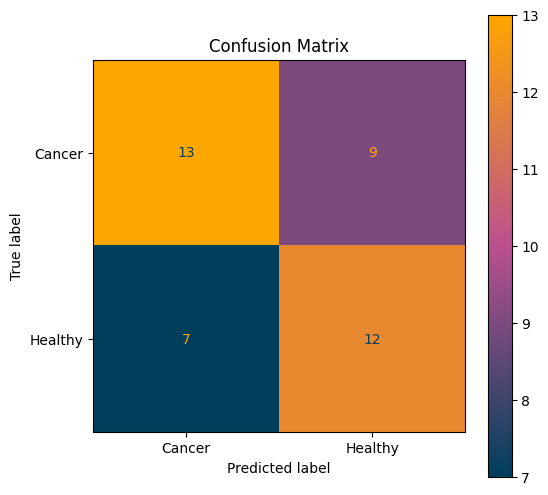

All Long a+
Confusion Matrix:
 [[14  8]
 [ 7 12]]
True Positives: 12
False Positives: 8
True Negatives: 14
False Negatives: 7

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.67      0.64      0.65        22
     Healthy       0.60      0.63      0.62        19

    accuracy                           0.63        41
   macro avg       0.63      0.63      0.63        41
weighted avg       0.64      0.63      0.63        41



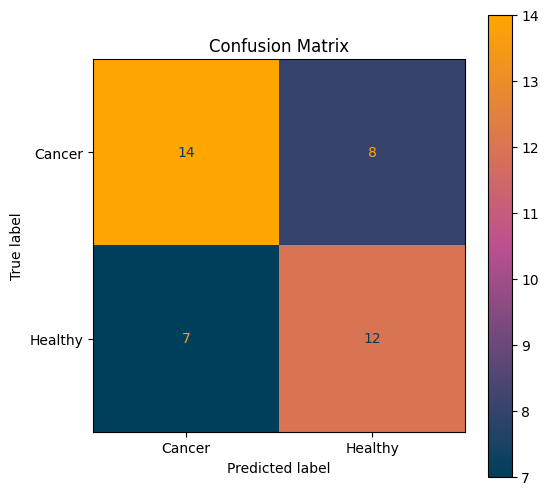

Top 2 Long a+ ext.
Confusion Matrix:
 [[16  6]
 [ 5 14]]
True Positives: 14
False Positives: 6
True Negatives: 16
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.76      0.73      0.74        22
     Healthy       0.70      0.74      0.72        19

    accuracy                           0.73        41
   macro avg       0.73      0.73      0.73        41
weighted avg       0.73      0.73      0.73        41



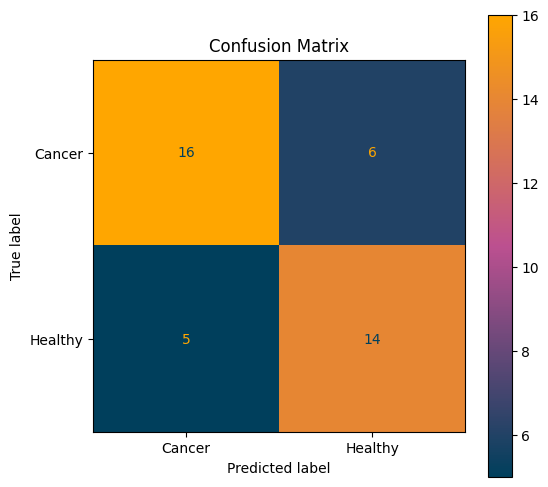

Top 3 Long a+ ext.
Confusion Matrix:
 [[18  4]
 [ 6 13]]
True Positives: 13
False Positives: 4
True Negatives: 18
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.75      0.82      0.78        22
     Healthy       0.76      0.68      0.72        19

    accuracy                           0.76        41
   macro avg       0.76      0.75      0.75        41
weighted avg       0.76      0.76      0.75        41



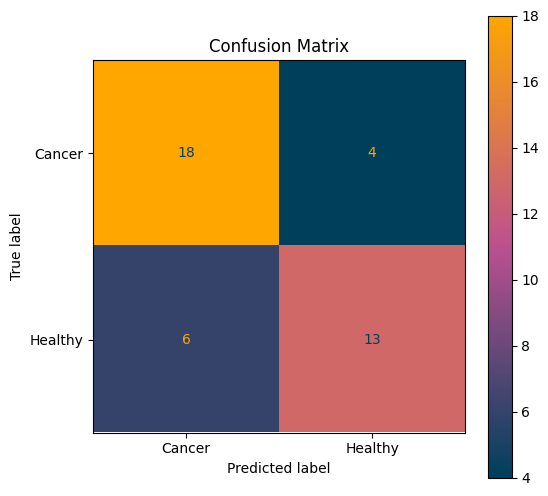

Top 5 Long a+ ext.
Confusion Matrix:
 [[17  5]
 [ 5 14]]
True Positives: 14
False Positives: 5
True Negatives: 17
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.77      0.77      0.77        22
     Healthy       0.74      0.74      0.74        19

    accuracy                           0.76        41
   macro avg       0.75      0.75      0.75        41
weighted avg       0.76      0.76      0.76        41



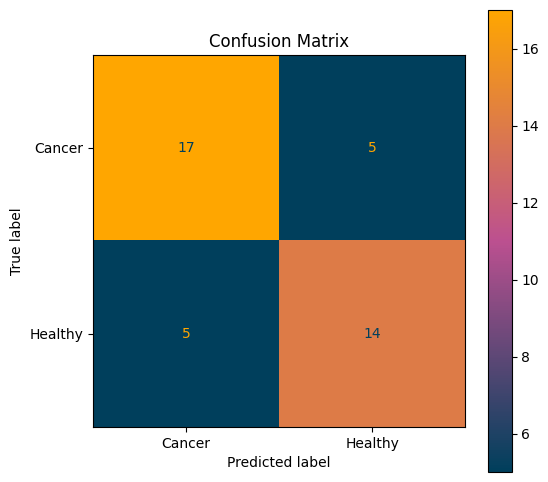

Top 12 Long a+ ext.
Confusion Matrix:
 [[17  5]
 [ 5 14]]
True Positives: 14
False Positives: 5
True Negatives: 17
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.77      0.77      0.77        22
     Healthy       0.74      0.74      0.74        19

    accuracy                           0.76        41
   macro avg       0.75      0.75      0.75        41
weighted avg       0.76      0.76      0.76        41



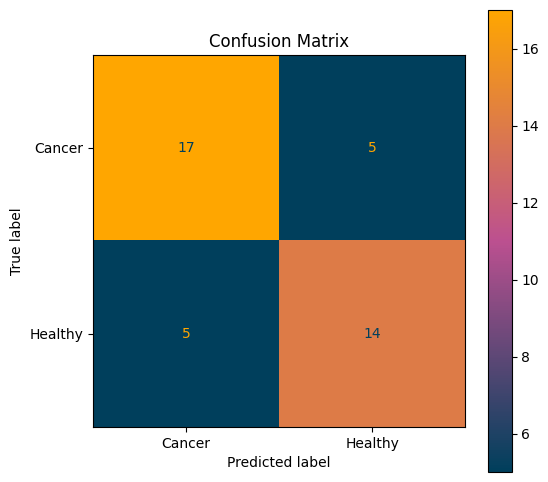

All Long a+ ext.
Confusion Matrix:
 [[17  5]
 [ 5 14]]
True Positives: 14
False Positives: 5
True Negatives: 17
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.77      0.77      0.77        22
     Healthy       0.74      0.74      0.74        19

    accuracy                           0.76        41
   macro avg       0.75      0.75      0.75        41
weighted avg       0.76      0.76      0.76        41



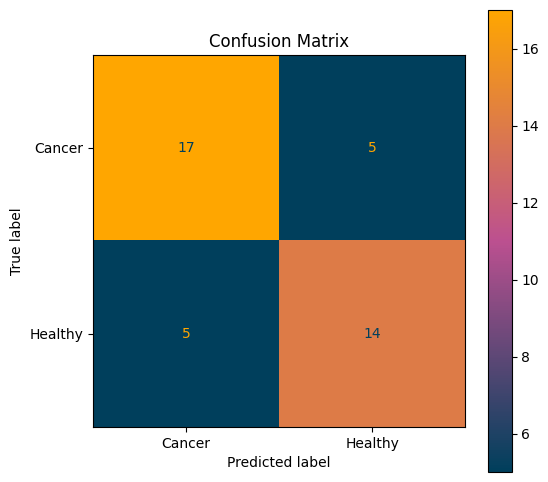

Top 2 Med. a+ ext.
Confusion Matrix:
 [[18  4]
 [ 6 13]]
True Positives: 13
False Positives: 4
True Negatives: 18
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.75      0.82      0.78        22
     Healthy       0.76      0.68      0.72        19

    accuracy                           0.76        41
   macro avg       0.76      0.75      0.75        41
weighted avg       0.76      0.76      0.75        41



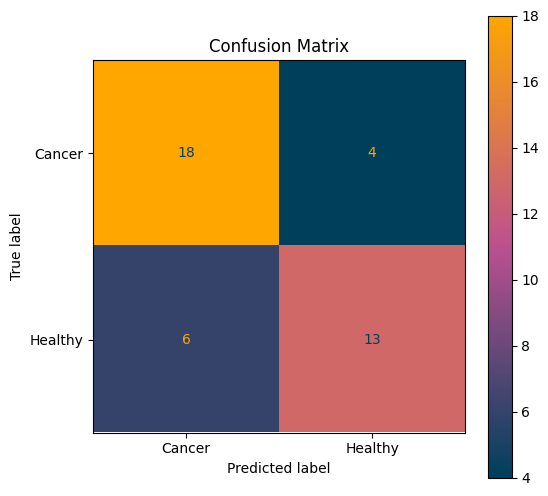

Top 3 Med. a+ ext.
Confusion Matrix:
 [[16  6]
 [ 6 13]]
True Positives: 13
False Positives: 6
True Negatives: 16
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.73      0.73      0.73        22
     Healthy       0.68      0.68      0.68        19

    accuracy                           0.71        41
   macro avg       0.71      0.71      0.71        41
weighted avg       0.71      0.71      0.71        41



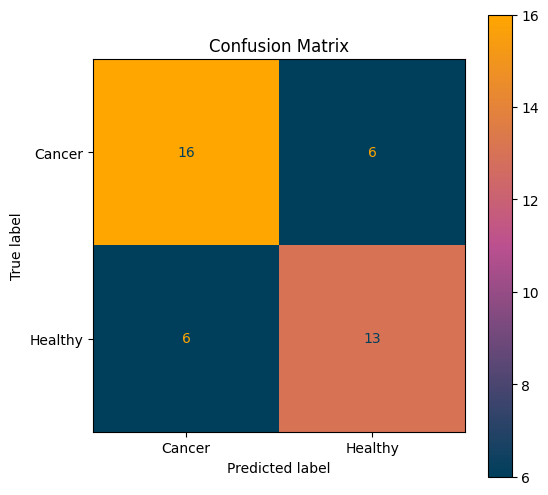

Top 5 Med. a+ ext.
Confusion Matrix:
 [[16  6]
 [ 5 14]]
True Positives: 14
False Positives: 6
True Negatives: 16
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.76      0.73      0.74        22
     Healthy       0.70      0.74      0.72        19

    accuracy                           0.73        41
   macro avg       0.73      0.73      0.73        41
weighted avg       0.73      0.73      0.73        41



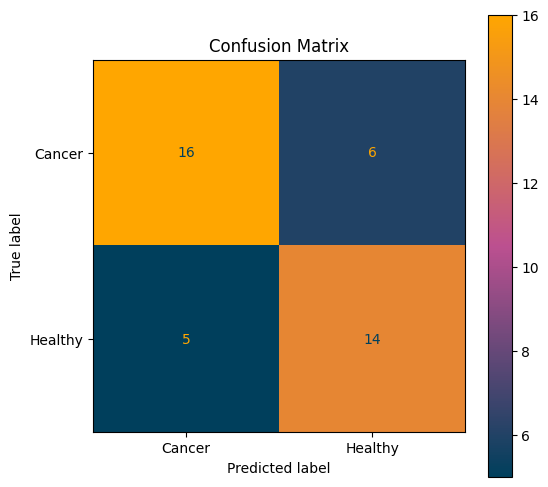

Top 12 Med. a+ ext.
Confusion Matrix:
 [[13  9]
 [ 7 12]]
True Positives: 12
False Positives: 9
True Negatives: 13
False Negatives: 7

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.65      0.59      0.62        22
     Healthy       0.57      0.63      0.60        19

    accuracy                           0.61        41
   macro avg       0.61      0.61      0.61        41
weighted avg       0.61      0.61      0.61        41



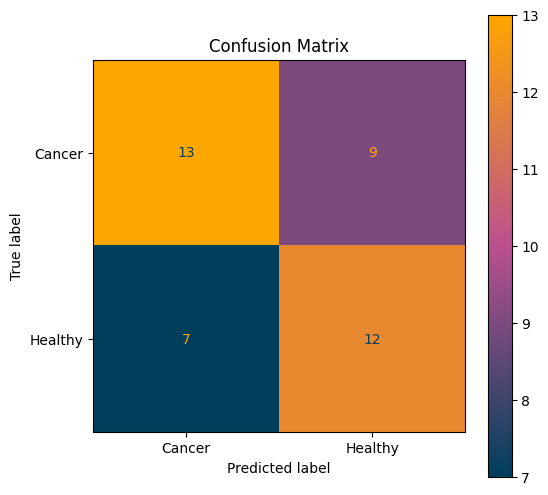

All Med. a+ ext.
Confusion Matrix:
 [[13  9]
 [ 7 12]]
True Positives: 12
False Positives: 9
True Negatives: 13
False Negatives: 7

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.65      0.59      0.62        22
     Healthy       0.57      0.63      0.60        19

    accuracy                           0.61        41
   macro avg       0.61      0.61      0.61        41
weighted avg       0.61      0.61      0.61        41



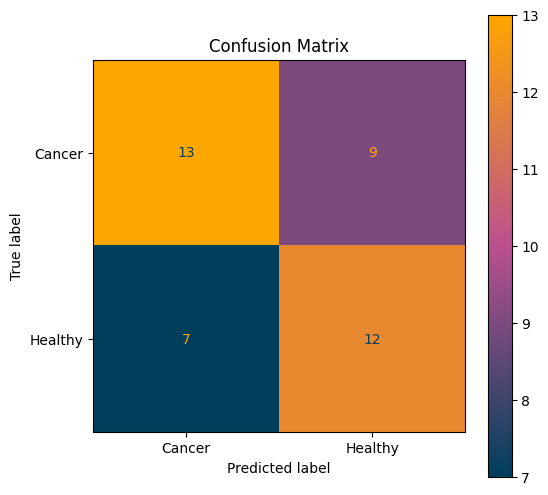

Top 2 Close skip 1
Confusion Matrix:
 [[12 10]
 [ 6 13]]
True Positives: 13
False Positives: 10
True Negatives: 12
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.67      0.55      0.60        22
     Healthy       0.57      0.68      0.62        19

    accuracy                           0.61        41
   macro avg       0.62      0.61      0.61        41
weighted avg       0.62      0.61      0.61        41



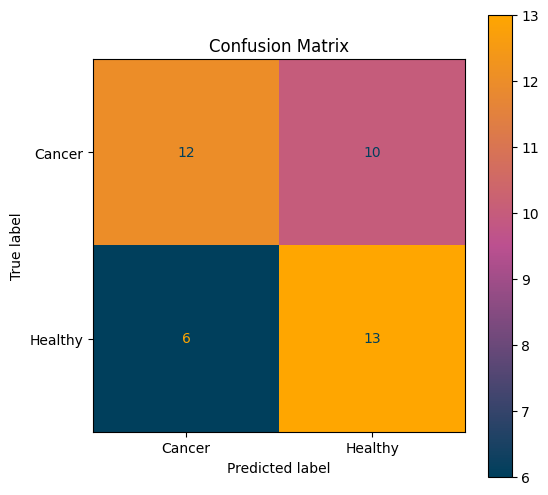

Top 3 Close skip 1
Confusion Matrix:
 [[15  7]
 [ 6 13]]
True Positives: 13
False Positives: 7
True Negatives: 15
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.71      0.68      0.70        22
     Healthy       0.65      0.68      0.67        19

    accuracy                           0.68        41
   macro avg       0.68      0.68      0.68        41
weighted avg       0.68      0.68      0.68        41



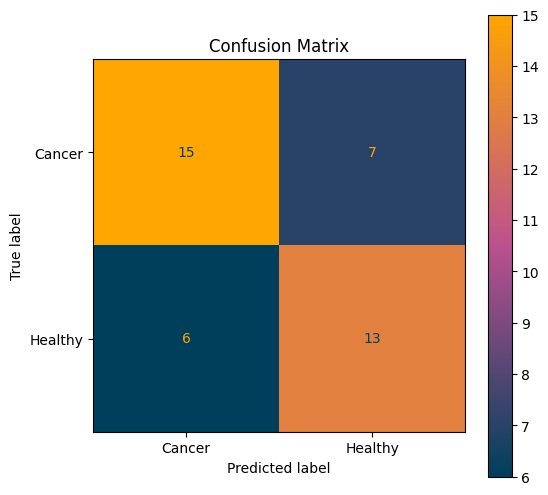

Top 5 Close skip 1
Confusion Matrix:
 [[15  7]
 [ 5 14]]
True Positives: 14
False Positives: 7
True Negatives: 15
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.75      0.68      0.71        22
     Healthy       0.67      0.74      0.70        19

    accuracy                           0.71        41
   macro avg       0.71      0.71      0.71        41
weighted avg       0.71      0.71      0.71        41



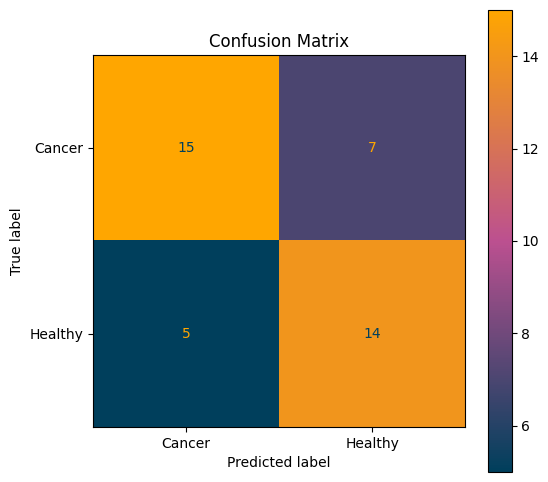

Top 12 Close skip 1
Confusion Matrix:
 [[15  7]
 [ 6 13]]
True Positives: 13
False Positives: 7
True Negatives: 15
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.71      0.68      0.70        22
     Healthy       0.65      0.68      0.67        19

    accuracy                           0.68        41
   macro avg       0.68      0.68      0.68        41
weighted avg       0.68      0.68      0.68        41



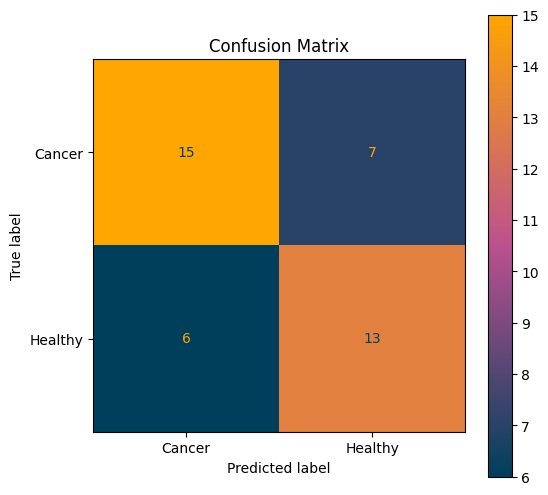

All Close skip 1
Confusion Matrix:
 [[15  7]
 [ 6 13]]
True Positives: 13
False Positives: 7
True Negatives: 15
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.71      0.68      0.70        22
     Healthy       0.65      0.68      0.67        19

    accuracy                           0.68        41
   macro avg       0.68      0.68      0.68        41
weighted avg       0.68      0.68      0.68        41



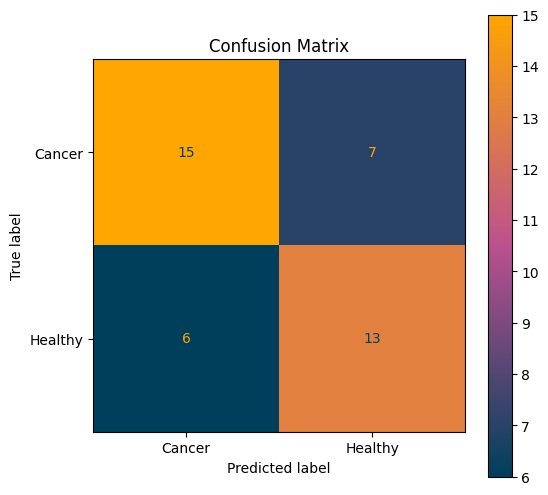

Top 2 All
Confusion Matrix:
 [[14  8]
 [ 4 15]]
True Positives: 15
False Positives: 8
True Negatives: 14
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.78      0.64      0.70        22
     Healthy       0.65      0.79      0.71        19

    accuracy                           0.71        41
   macro avg       0.71      0.71      0.71        41
weighted avg       0.72      0.71      0.71        41



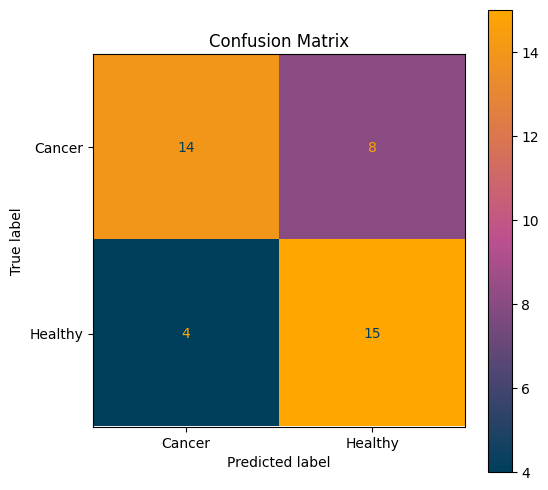

Top 3 All
Confusion Matrix:
 [[15  7]
 [ 5 14]]
True Positives: 14
False Positives: 7
True Negatives: 15
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.75      0.68      0.71        22
     Healthy       0.67      0.74      0.70        19

    accuracy                           0.71        41
   macro avg       0.71      0.71      0.71        41
weighted avg       0.71      0.71      0.71        41



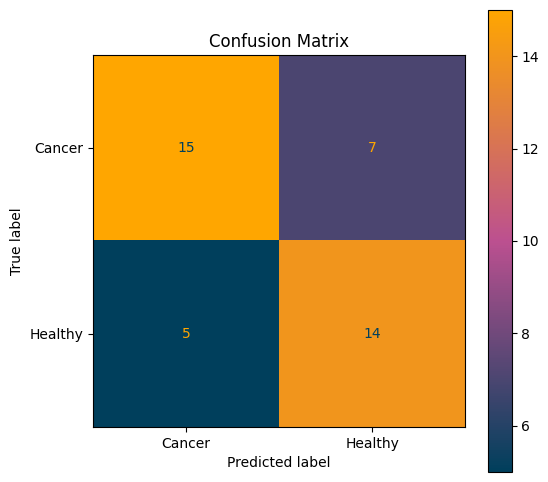

Top 5 All
Confusion Matrix:
 [[15  7]
 [ 4 15]]
True Positives: 15
False Positives: 7
True Negatives: 15
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.79      0.68      0.73        22
     Healthy       0.68      0.79      0.73        19

    accuracy                           0.73        41
   macro avg       0.74      0.74      0.73        41
weighted avg       0.74      0.73      0.73        41



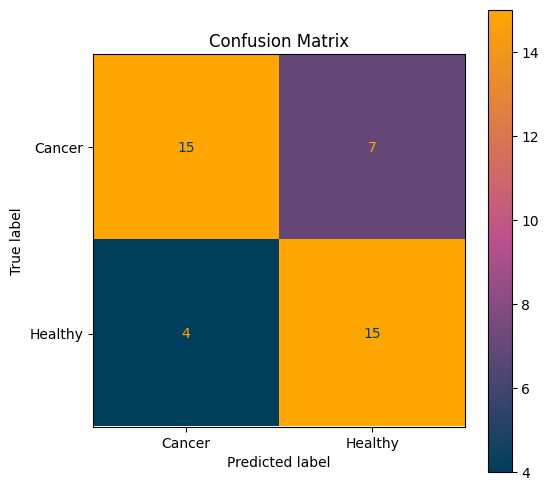

Top 12 All
Confusion Matrix:
 [[15  7]
 [ 4 15]]
True Positives: 15
False Positives: 7
True Negatives: 15
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.79      0.68      0.73        22
     Healthy       0.68      0.79      0.73        19

    accuracy                           0.73        41
   macro avg       0.74      0.74      0.73        41
weighted avg       0.74      0.73      0.73        41



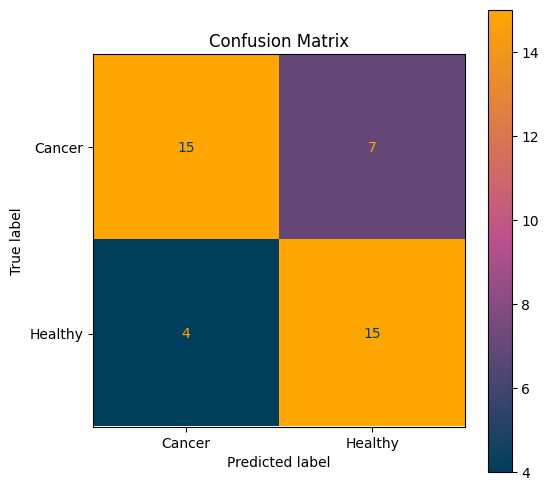

All All
Confusion Matrix:
 [[15  7]
 [ 5 14]]
True Positives: 14
False Positives: 7
True Negatives: 15
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.75      0.68      0.71        22
     Healthy       0.67      0.74      0.70        19

    accuracy                           0.71        41
   macro avg       0.71      0.71      0.71        41
weighted avg       0.71      0.71      0.71        41



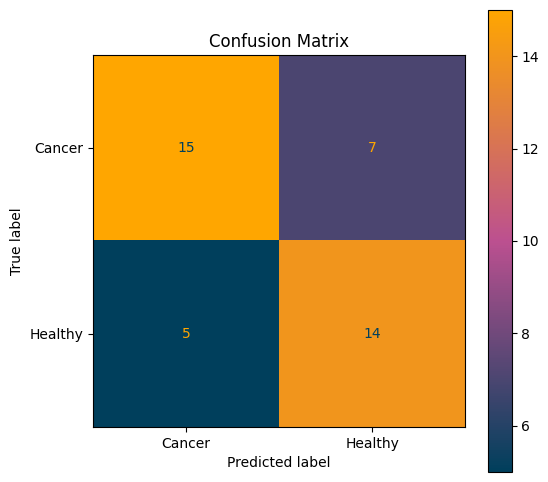

Train patients: [ 0  1  2  4  6  8  9 10 11 12 13 14 15 16 18 19 21 22 23 24 25 28 31 32
 33 34 35 36 37 38 39 40 41 42 43 44 47 49 50 52 53 54 55 56 57 58 59 60
 61 62 63 64 65 66 67 68 70 72 73 74 75 76 79 80 82 83 84 85 87 89 92 94
 95 96 97 99]
Test patients: [77 48 29 46 27  7 45 51 78 86 81 91 90  3 69 88 30 20]

Fold 2: 81.1% train / 18.9% test
Fold 2: 81.1% train / 18.9% test
  Training: 146 samples from 76 patients
  Testing:  34 samples from 18 patients
Top 2 Long a+
Confusion Matrix:
 [[15  3]
 [ 4 12]]
True Positives: 12
False Positives: 3
True Negatives: 15
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.79      0.83      0.81        18
     Healthy       0.80      0.75      0.77        16

    accuracy                           0.79        34
   macro avg       0.79      0.79      0.79        34
weighted avg       0.79      0.79      0.79        34



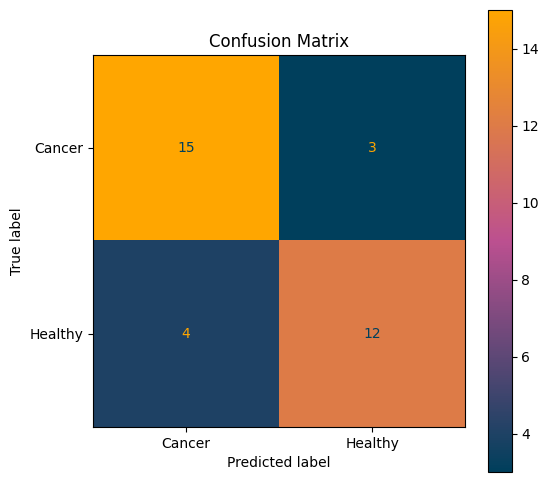

Top 3 Long a+
Confusion Matrix:
 [[15  3]
 [ 4 12]]
True Positives: 12
False Positives: 3
True Negatives: 15
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.79      0.83      0.81        18
     Healthy       0.80      0.75      0.77        16

    accuracy                           0.79        34
   macro avg       0.79      0.79      0.79        34
weighted avg       0.79      0.79      0.79        34



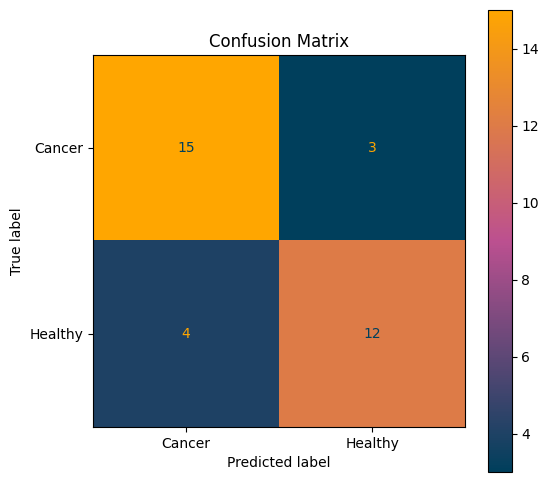

Top 5 Long a+
Confusion Matrix:
 [[16  2]
 [ 3 13]]
True Positives: 13
False Positives: 2
True Negatives: 16
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.84      0.89      0.86        18
     Healthy       0.87      0.81      0.84        16

    accuracy                           0.85        34
   macro avg       0.85      0.85      0.85        34
weighted avg       0.85      0.85      0.85        34



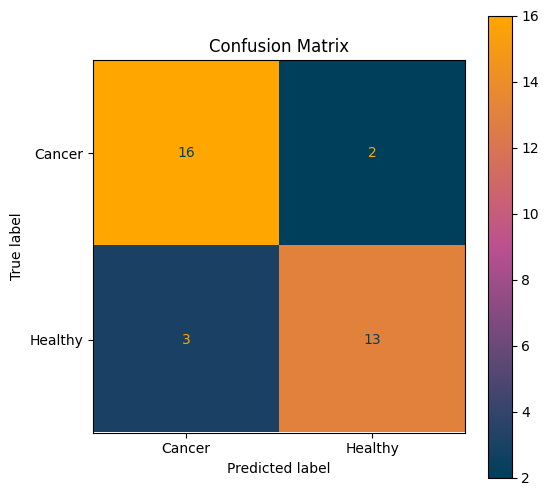

Top 12 Long a+
Confusion Matrix:
 [[16  2]
 [ 4 12]]
True Positives: 12
False Positives: 2
True Negatives: 16
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.80      0.89      0.84        18
     Healthy       0.86      0.75      0.80        16

    accuracy                           0.82        34
   macro avg       0.83      0.82      0.82        34
weighted avg       0.83      0.82      0.82        34



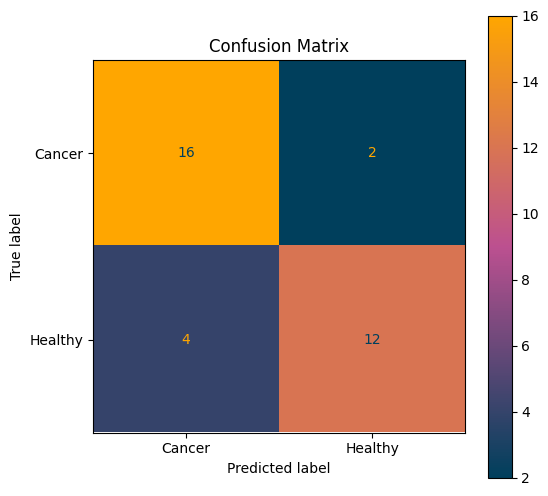

All Long a+
Confusion Matrix:
 [[17  1]
 [ 6 10]]
True Positives: 10
False Positives: 1
True Negatives: 17
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.74      0.94      0.83        18
     Healthy       0.91      0.62      0.74        16

    accuracy                           0.79        34
   macro avg       0.82      0.78      0.79        34
weighted avg       0.82      0.79      0.79        34



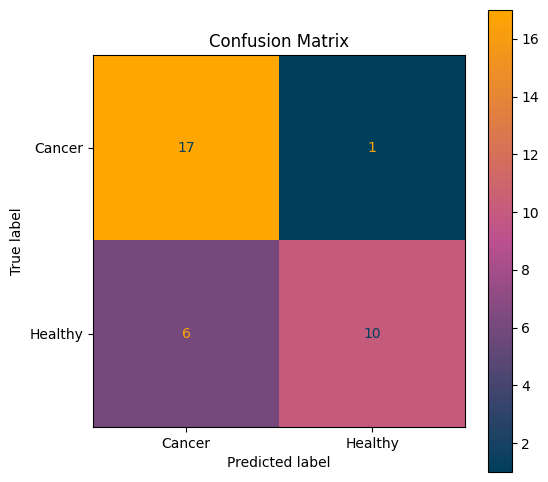

Top 2 Long a+ ext.
Confusion Matrix:
 [[14  4]
 [ 4 12]]
True Positives: 12
False Positives: 4
True Negatives: 14
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.78      0.78      0.78        18
     Healthy       0.75      0.75      0.75        16

    accuracy                           0.76        34
   macro avg       0.76      0.76      0.76        34
weighted avg       0.76      0.76      0.76        34



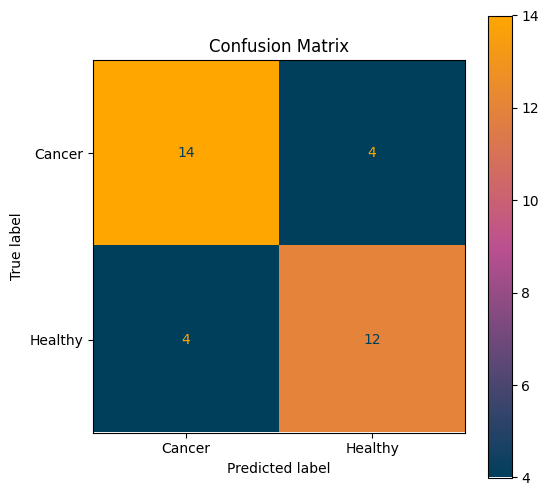

Top 3 Long a+ ext.
Confusion Matrix:
 [[16  2]
 [ 5 11]]
True Positives: 11
False Positives: 2
True Negatives: 16
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.76      0.89      0.82        18
     Healthy       0.85      0.69      0.76        16

    accuracy                           0.79        34
   macro avg       0.80      0.79      0.79        34
weighted avg       0.80      0.79      0.79        34



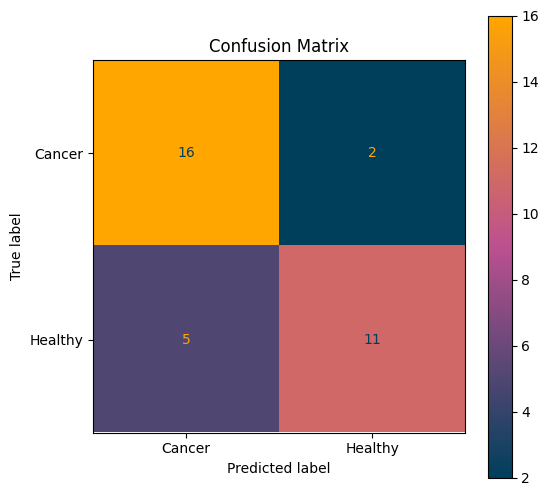

Top 5 Long a+ ext.
Confusion Matrix:
 [[17  1]
 [ 5 11]]
True Positives: 11
False Positives: 1
True Negatives: 17
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.77      0.94      0.85        18
     Healthy       0.92      0.69      0.79        16

    accuracy                           0.82        34
   macro avg       0.84      0.82      0.82        34
weighted avg       0.84      0.82      0.82        34



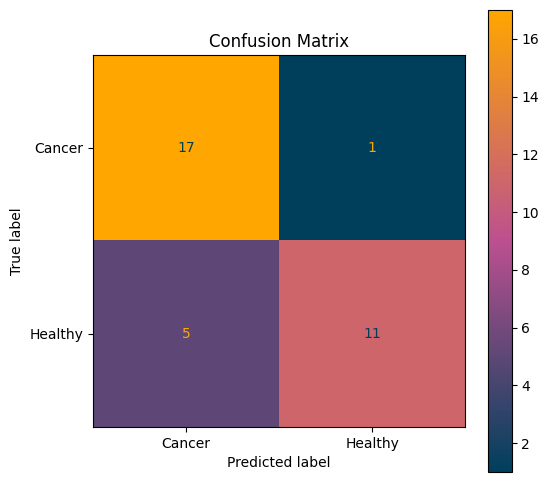

Top 12 Long a+ ext.
Confusion Matrix:
 [[16  2]
 [ 4 12]]
True Positives: 12
False Positives: 2
True Negatives: 16
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.80      0.89      0.84        18
     Healthy       0.86      0.75      0.80        16

    accuracy                           0.82        34
   macro avg       0.83      0.82      0.82        34
weighted avg       0.83      0.82      0.82        34



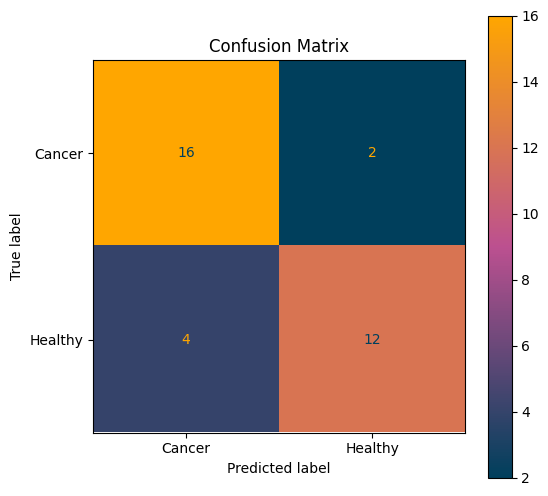

All Long a+ ext.
Confusion Matrix:
 [[14  4]
 [ 4 12]]
True Positives: 12
False Positives: 4
True Negatives: 14
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.78      0.78      0.78        18
     Healthy       0.75      0.75      0.75        16

    accuracy                           0.76        34
   macro avg       0.76      0.76      0.76        34
weighted avg       0.76      0.76      0.76        34



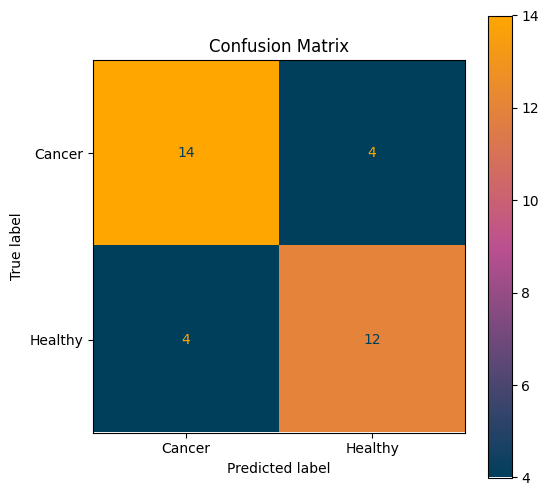

Top 2 Med. a+ ext.
Confusion Matrix:
 [[13  5]
 [ 1 15]]
True Positives: 15
False Positives: 5
True Negatives: 13
False Negatives: 1

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.93      0.72      0.81        18
     Healthy       0.75      0.94      0.83        16

    accuracy                           0.82        34
   macro avg       0.84      0.83      0.82        34
weighted avg       0.84      0.82      0.82        34



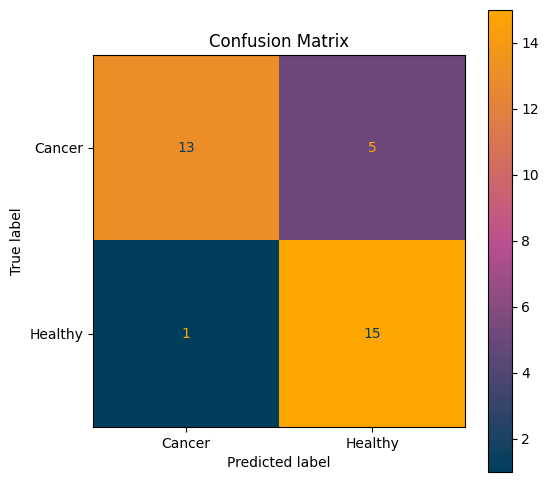

Top 3 Med. a+ ext.
Confusion Matrix:
 [[13  5]
 [ 3 13]]
True Positives: 13
False Positives: 5
True Negatives: 13
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.81      0.72      0.76        18
     Healthy       0.72      0.81      0.76        16

    accuracy                           0.76        34
   macro avg       0.77      0.77      0.76        34
weighted avg       0.77      0.76      0.76        34



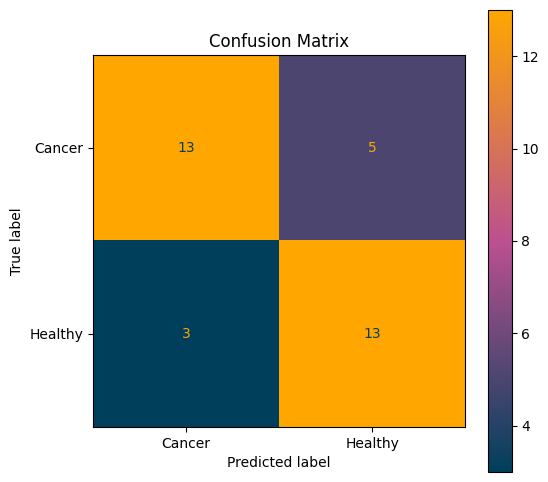

Top 5 Med. a+ ext.
Confusion Matrix:
 [[14  4]
 [ 3 13]]
True Positives: 13
False Positives: 4
True Negatives: 14
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.82      0.78      0.80        18
     Healthy       0.76      0.81      0.79        16

    accuracy                           0.79        34
   macro avg       0.79      0.80      0.79        34
weighted avg       0.80      0.79      0.79        34



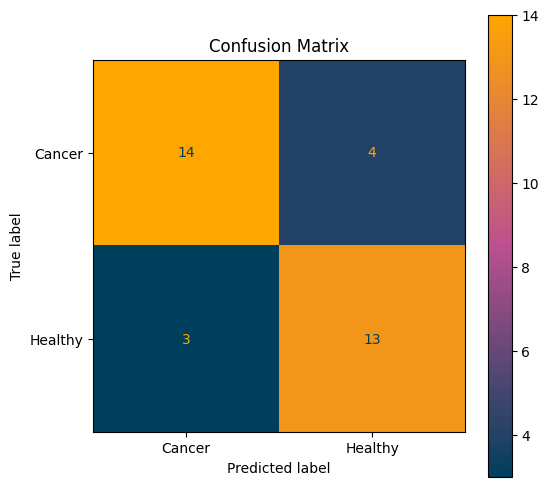

Top 12 Med. a+ ext.
Confusion Matrix:
 [[15  3]
 [ 3 13]]
True Positives: 13
False Positives: 3
True Negatives: 15
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.83      0.83      0.83        18
     Healthy       0.81      0.81      0.81        16

    accuracy                           0.82        34
   macro avg       0.82      0.82      0.82        34
weighted avg       0.82      0.82      0.82        34



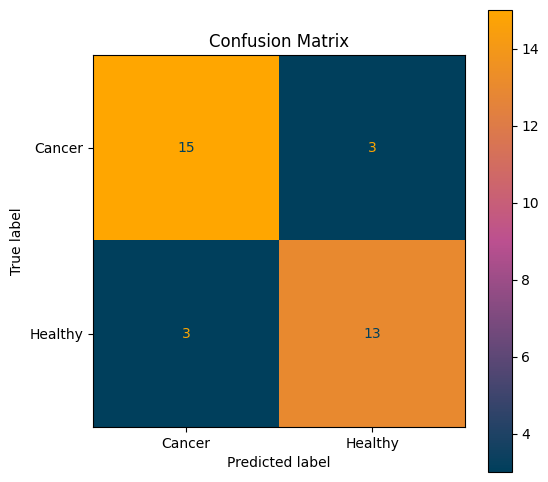

All Med. a+ ext.
Confusion Matrix:
 [[14  4]
 [ 2 14]]
True Positives: 14
False Positives: 4
True Negatives: 14
False Negatives: 2

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.88      0.78      0.82        18
     Healthy       0.78      0.88      0.82        16

    accuracy                           0.82        34
   macro avg       0.83      0.83      0.82        34
weighted avg       0.83      0.82      0.82        34



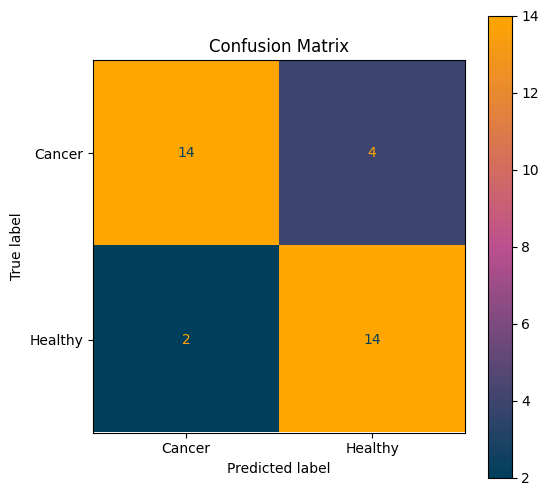

Top 2 Close skip 1
Confusion Matrix:
 [[15  3]
 [ 6 10]]
True Positives: 10
False Positives: 3
True Negatives: 15
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.71      0.83      0.77        18
     Healthy       0.77      0.62      0.69        16

    accuracy                           0.74        34
   macro avg       0.74      0.73      0.73        34
weighted avg       0.74      0.74      0.73        34



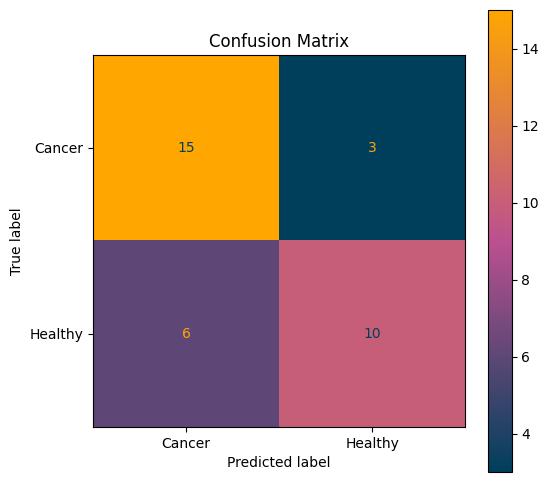

Top 3 Close skip 1
Confusion Matrix:
 [[14  4]
 [ 4 12]]
True Positives: 12
False Positives: 4
True Negatives: 14
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.78      0.78      0.78        18
     Healthy       0.75      0.75      0.75        16

    accuracy                           0.76        34
   macro avg       0.76      0.76      0.76        34
weighted avg       0.76      0.76      0.76        34



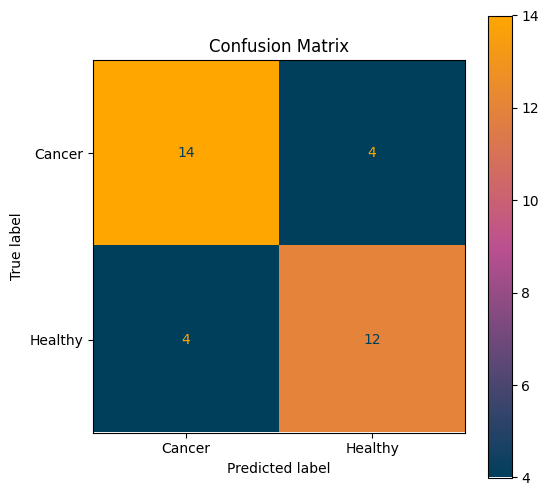

Top 5 Close skip 1
Confusion Matrix:
 [[14  4]
 [ 5 11]]
True Positives: 11
False Positives: 4
True Negatives: 14
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.74      0.78      0.76        18
     Healthy       0.73      0.69      0.71        16

    accuracy                           0.74        34
   macro avg       0.74      0.73      0.73        34
weighted avg       0.74      0.74      0.73        34



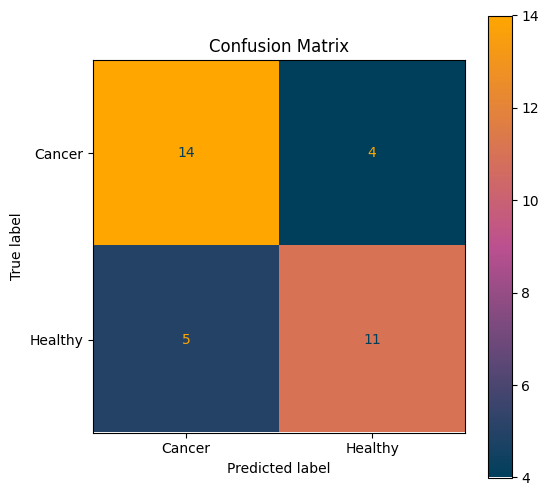

Top 12 Close skip 1
Confusion Matrix:
 [[14  4]
 [ 5 11]]
True Positives: 11
False Positives: 4
True Negatives: 14
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.74      0.78      0.76        18
     Healthy       0.73      0.69      0.71        16

    accuracy                           0.74        34
   macro avg       0.74      0.73      0.73        34
weighted avg       0.74      0.74      0.73        34



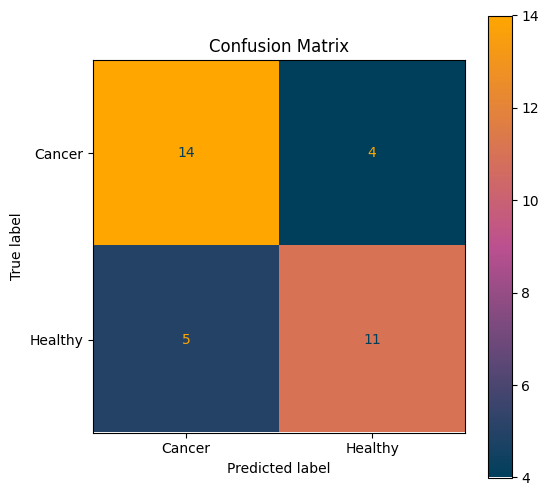

All Close skip 1
Confusion Matrix:
 [[14  4]
 [ 5 11]]
True Positives: 11
False Positives: 4
True Negatives: 14
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.74      0.78      0.76        18
     Healthy       0.73      0.69      0.71        16

    accuracy                           0.74        34
   macro avg       0.74      0.73      0.73        34
weighted avg       0.74      0.74      0.73        34



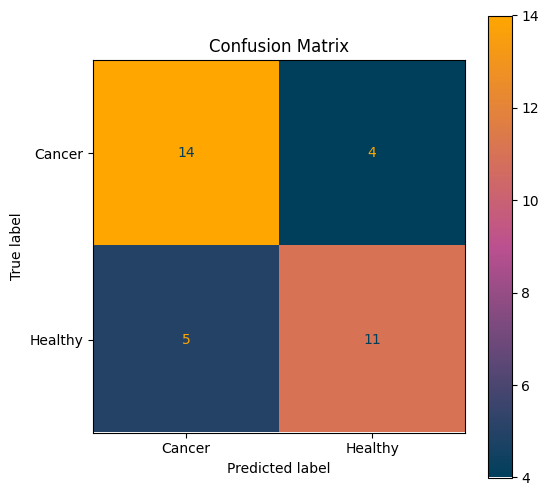

Top 2 All
Confusion Matrix:
 [[15  3]
 [ 3 13]]
True Positives: 13
False Positives: 3
True Negatives: 15
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.83      0.83      0.83        18
     Healthy       0.81      0.81      0.81        16

    accuracy                           0.82        34
   macro avg       0.82      0.82      0.82        34
weighted avg       0.82      0.82      0.82        34



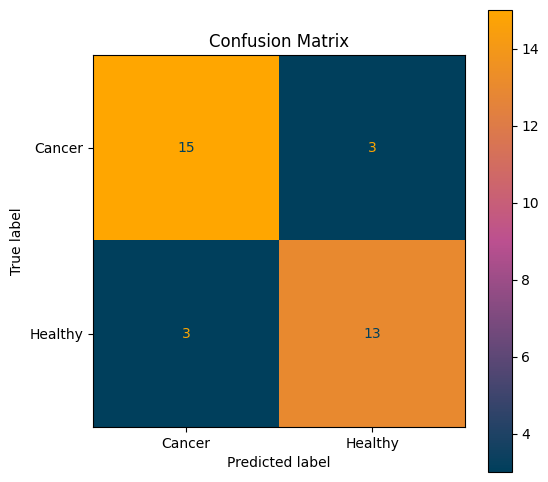

Top 3 All
Confusion Matrix:
 [[15  3]
 [ 3 13]]
True Positives: 13
False Positives: 3
True Negatives: 15
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.83      0.83      0.83        18
     Healthy       0.81      0.81      0.81        16

    accuracy                           0.82        34
   macro avg       0.82      0.82      0.82        34
weighted avg       0.82      0.82      0.82        34



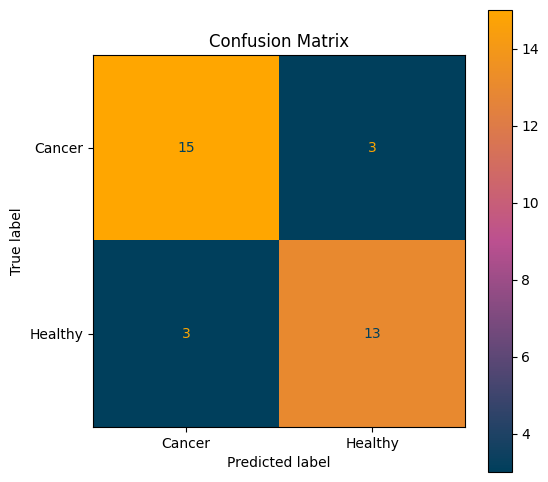

Top 5 All
Confusion Matrix:
 [[15  3]
 [ 4 12]]
True Positives: 12
False Positives: 3
True Negatives: 15
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.79      0.83      0.81        18
     Healthy       0.80      0.75      0.77        16

    accuracy                           0.79        34
   macro avg       0.79      0.79      0.79        34
weighted avg       0.79      0.79      0.79        34



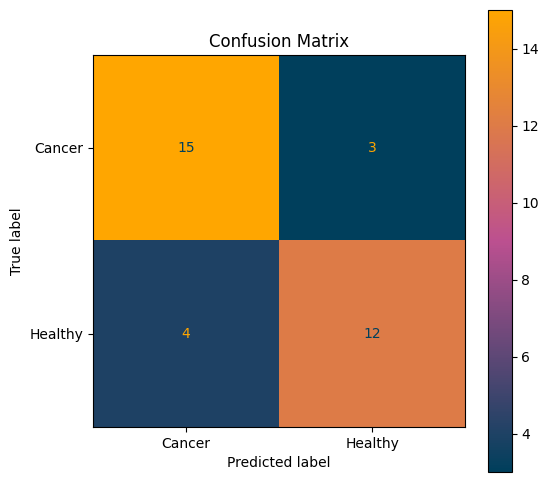

Top 12 All
Confusion Matrix:
 [[14  4]
 [ 3 13]]
True Positives: 13
False Positives: 4
True Negatives: 14
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.82      0.78      0.80        18
     Healthy       0.76      0.81      0.79        16

    accuracy                           0.79        34
   macro avg       0.79      0.80      0.79        34
weighted avg       0.80      0.79      0.79        34



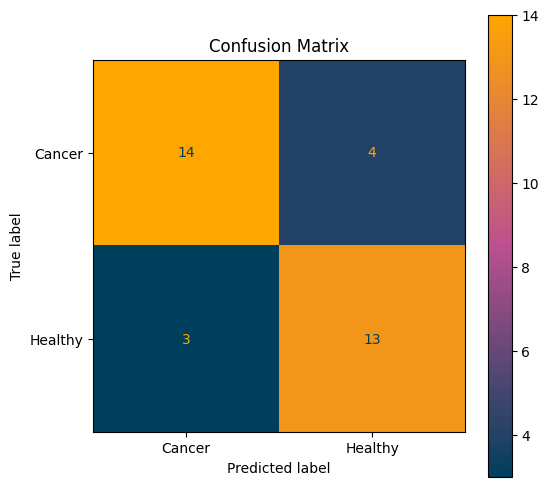

All All
Confusion Matrix:
 [[14  4]
 [ 3 13]]
True Positives: 13
False Positives: 4
True Negatives: 14
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.82      0.78      0.80        18
     Healthy       0.76      0.81      0.79        16

    accuracy                           0.79        34
   macro avg       0.79      0.80      0.79        34
weighted avg       0.80      0.79      0.79        34



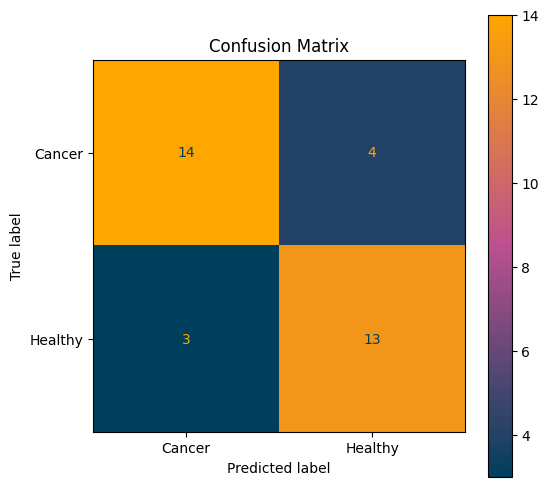

Train patients: [ 1  2  3  7  8  9 10 11 12 13 14 15 18 20 21 22 23 24 25 27 28 29 30 32
 33 34 35 36 38 39 40 42 45 46 47 48 49 50 51 52 54 55 59 60 61 63 64 65
 67 68 69 70 72 73 74 75 76 77 78 79 80 81 82 83 84 86 87 88 90 91 92 94
 95 96 97 99]
Test patients: [57 58 85 66 62 44  4 16 19 43 41  6 89 56  0 37 31 53]

Fold 3: 78.9% train / 21.1% test
Fold 3: 78.9% train / 21.1% test
  Training: 142 samples from 76 patients
  Testing:  38 samples from 18 patients
Top 2 Long a+
Confusion Matrix:
 [[14  8]
 [ 2 14]]
True Positives: 14
False Positives: 8
True Negatives: 14
False Negatives: 2

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.88      0.64      0.74        22
     Healthy       0.64      0.88      0.74        16

    accuracy                           0.74        38
   macro avg       0.76      0.76      0.74        38
weighted avg       0.77      0.74      0.74        38



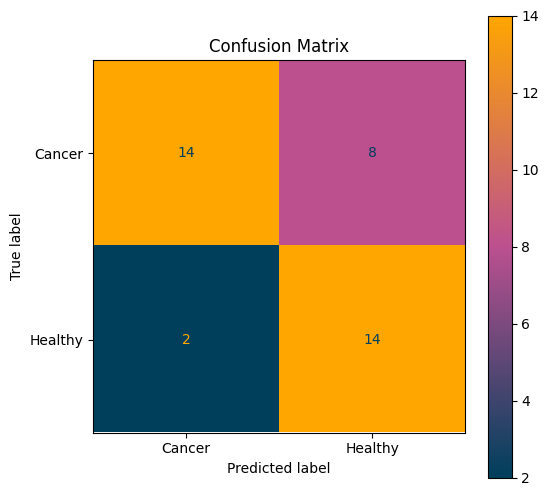

Top 3 Long a+
Confusion Matrix:
 [[14  8]
 [ 4 12]]
True Positives: 12
False Positives: 8
True Negatives: 14
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.78      0.64      0.70        22
     Healthy       0.60      0.75      0.67        16

    accuracy                           0.68        38
   macro avg       0.69      0.69      0.68        38
weighted avg       0.70      0.68      0.69        38



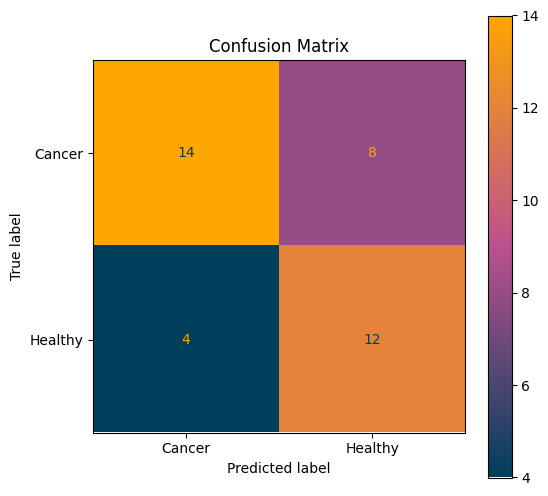

Top 5 Long a+
Confusion Matrix:
 [[14  8]
 [ 6 10]]
True Positives: 10
False Positives: 8
True Negatives: 14
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.70      0.64      0.67        22
     Healthy       0.56      0.62      0.59        16

    accuracy                           0.63        38
   macro avg       0.63      0.63      0.63        38
weighted avg       0.64      0.63      0.63        38



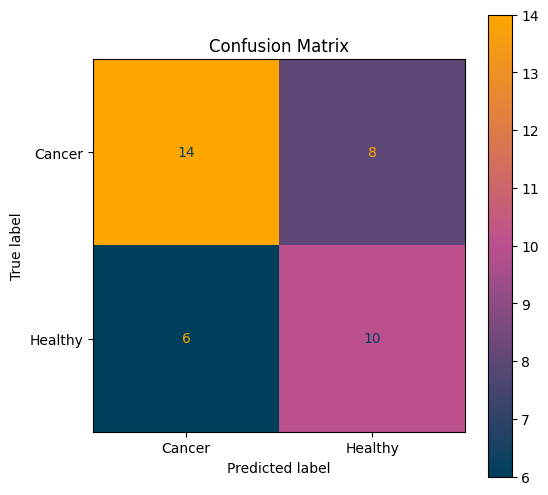

Top 12 Long a+
Confusion Matrix:
 [[16  6]
 [ 4 12]]
True Positives: 12
False Positives: 6
True Negatives: 16
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.80      0.73      0.76        22
     Healthy       0.67      0.75      0.71        16

    accuracy                           0.74        38
   macro avg       0.73      0.74      0.73        38
weighted avg       0.74      0.74      0.74        38



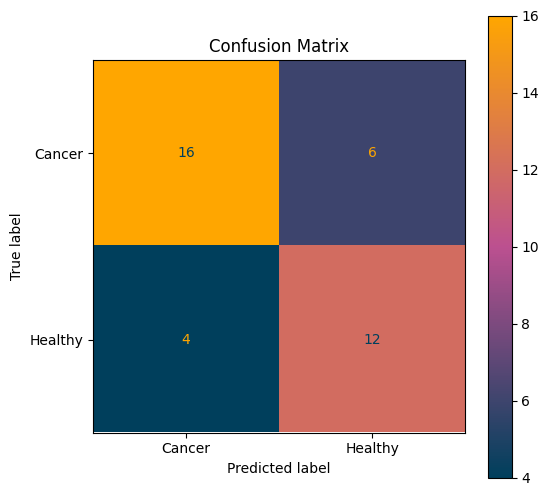

All Long a+
Confusion Matrix:
 [[17  5]
 [ 6 10]]
True Positives: 10
False Positives: 5
True Negatives: 17
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.74      0.77      0.76        22
     Healthy       0.67      0.62      0.65        16

    accuracy                           0.71        38
   macro avg       0.70      0.70      0.70        38
weighted avg       0.71      0.71      0.71        38



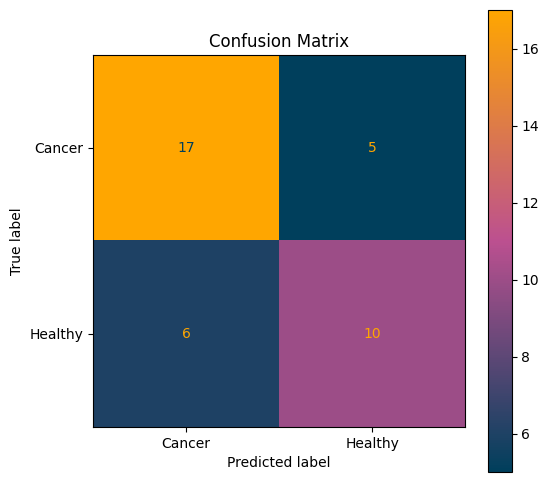

Top 2 Long a+ ext.
Confusion Matrix:
 [[16  6]
 [ 4 12]]
True Positives: 12
False Positives: 6
True Negatives: 16
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.80      0.73      0.76        22
     Healthy       0.67      0.75      0.71        16

    accuracy                           0.74        38
   macro avg       0.73      0.74      0.73        38
weighted avg       0.74      0.74      0.74        38



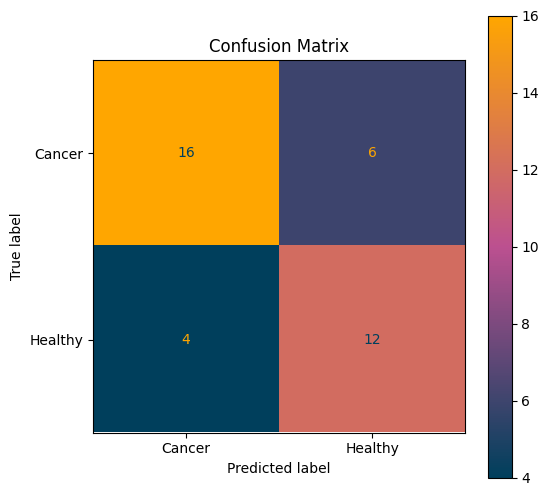

Top 3 Long a+ ext.
Confusion Matrix:
 [[17  5]
 [ 3 13]]
True Positives: 13
False Positives: 5
True Negatives: 17
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.85      0.77      0.81        22
     Healthy       0.72      0.81      0.76        16

    accuracy                           0.79        38
   macro avg       0.79      0.79      0.79        38
weighted avg       0.80      0.79      0.79        38



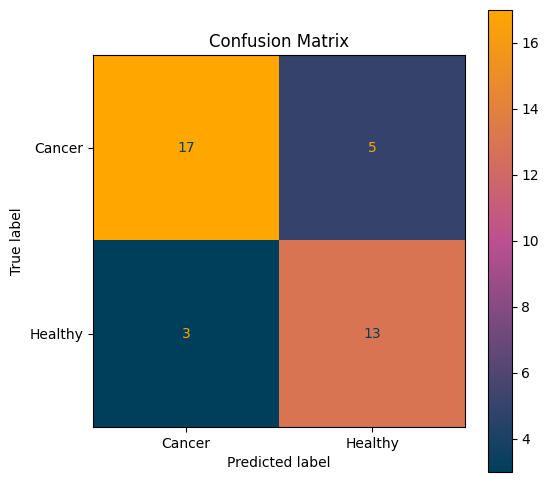

Top 5 Long a+ ext.
Confusion Matrix:
 [[16  6]
 [ 3 13]]
True Positives: 13
False Positives: 6
True Negatives: 16
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.84      0.73      0.78        22
     Healthy       0.68      0.81      0.74        16

    accuracy                           0.76        38
   macro avg       0.76      0.77      0.76        38
weighted avg       0.78      0.76      0.76        38



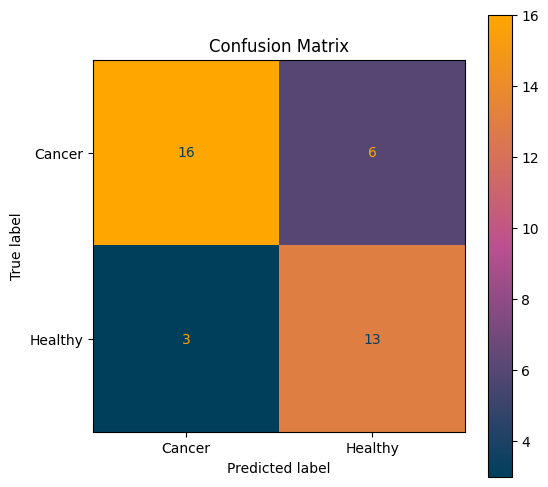

Top 12 Long a+ ext.
Confusion Matrix:
 [[15  7]
 [ 2 14]]
True Positives: 14
False Positives: 7
True Negatives: 15
False Negatives: 2

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.88      0.68      0.77        22
     Healthy       0.67      0.88      0.76        16

    accuracy                           0.76        38
   macro avg       0.77      0.78      0.76        38
weighted avg       0.79      0.76      0.76        38



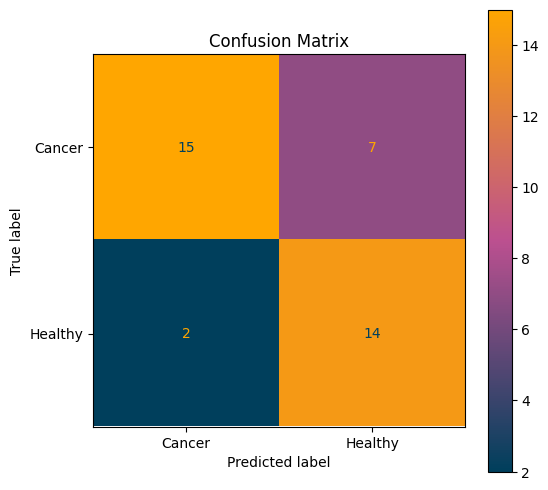

All Long a+ ext.
Confusion Matrix:
 [[15  7]
 [ 3 13]]
True Positives: 13
False Positives: 7
True Negatives: 15
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.83      0.68      0.75        22
     Healthy       0.65      0.81      0.72        16

    accuracy                           0.74        38
   macro avg       0.74      0.75      0.74        38
weighted avg       0.76      0.74      0.74        38



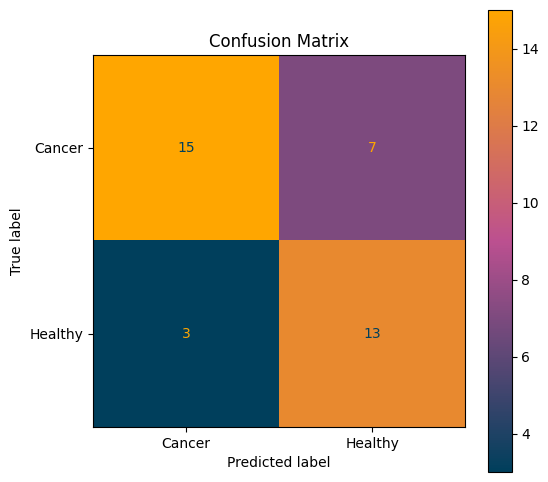

Top 2 Med. a+ ext.
Confusion Matrix:
 [[14  8]
 [ 3 13]]
True Positives: 13
False Positives: 8
True Negatives: 14
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.82      0.64      0.72        22
     Healthy       0.62      0.81      0.70        16

    accuracy                           0.71        38
   macro avg       0.72      0.72      0.71        38
weighted avg       0.74      0.71      0.71        38



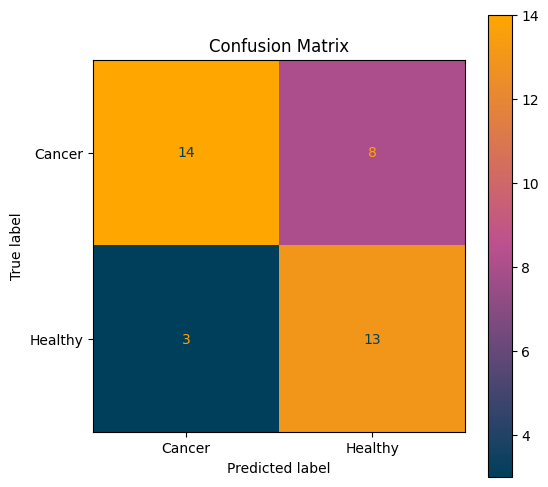

Top 3 Med. a+ ext.
Confusion Matrix:
 [[15  7]
 [ 2 14]]
True Positives: 14
False Positives: 7
True Negatives: 15
False Negatives: 2

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.88      0.68      0.77        22
     Healthy       0.67      0.88      0.76        16

    accuracy                           0.76        38
   macro avg       0.77      0.78      0.76        38
weighted avg       0.79      0.76      0.76        38



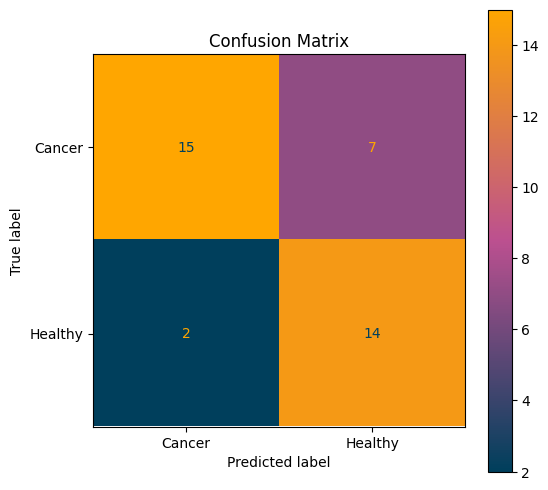

Top 5 Med. a+ ext.
Confusion Matrix:
 [[15  7]
 [ 2 14]]
True Positives: 14
False Positives: 7
True Negatives: 15
False Negatives: 2

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.88      0.68      0.77        22
     Healthy       0.67      0.88      0.76        16

    accuracy                           0.76        38
   macro avg       0.77      0.78      0.76        38
weighted avg       0.79      0.76      0.76        38



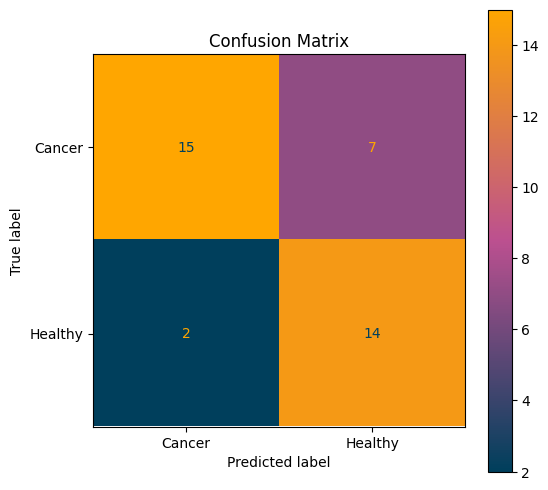

Top 12 Med. a+ ext.
Confusion Matrix:
 [[14  8]
 [ 3 13]]
True Positives: 13
False Positives: 8
True Negatives: 14
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.82      0.64      0.72        22
     Healthy       0.62      0.81      0.70        16

    accuracy                           0.71        38
   macro avg       0.72      0.72      0.71        38
weighted avg       0.74      0.71      0.71        38



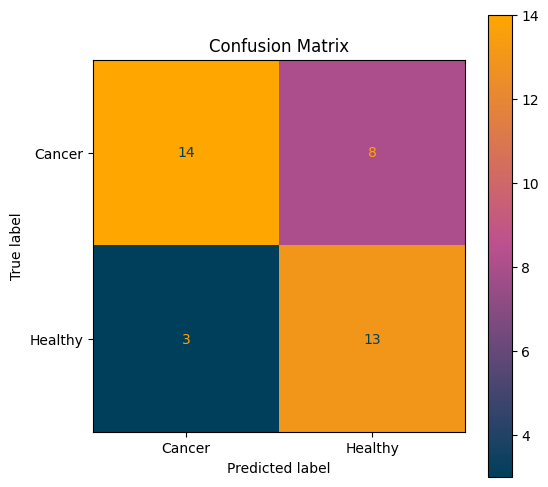

All Med. a+ ext.
Confusion Matrix:
 [[14  8]
 [ 3 13]]
True Positives: 13
False Positives: 8
True Negatives: 14
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.82      0.64      0.72        22
     Healthy       0.62      0.81      0.70        16

    accuracy                           0.71        38
   macro avg       0.72      0.72      0.71        38
weighted avg       0.74      0.71      0.71        38



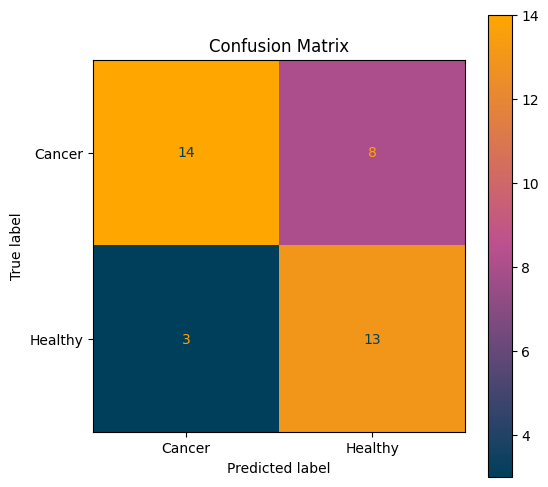

Top 2 Close skip 1
Confusion Matrix:
 [[14  8]
 [ 1 15]]
True Positives: 15
False Positives: 8
True Negatives: 14
False Negatives: 1

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.93      0.64      0.76        22
     Healthy       0.65      0.94      0.77        16

    accuracy                           0.76        38
   macro avg       0.79      0.79      0.76        38
weighted avg       0.81      0.76      0.76        38



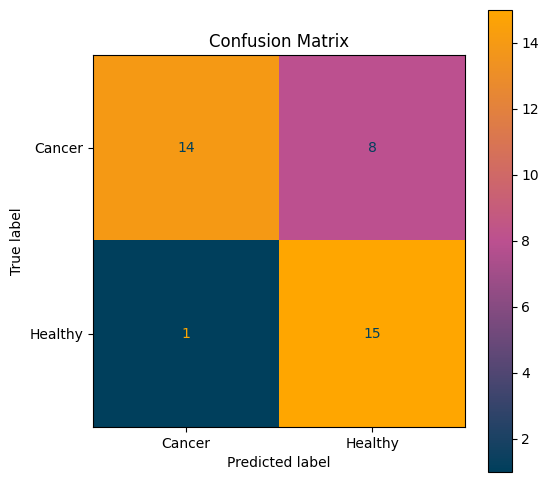

Top 3 Close skip 1
Confusion Matrix:
 [[15  7]
 [ 1 15]]
True Positives: 15
False Positives: 7
True Negatives: 15
False Negatives: 1

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.94      0.68      0.79        22
     Healthy       0.68      0.94      0.79        16

    accuracy                           0.79        38
   macro avg       0.81      0.81      0.79        38
weighted avg       0.83      0.79      0.79        38



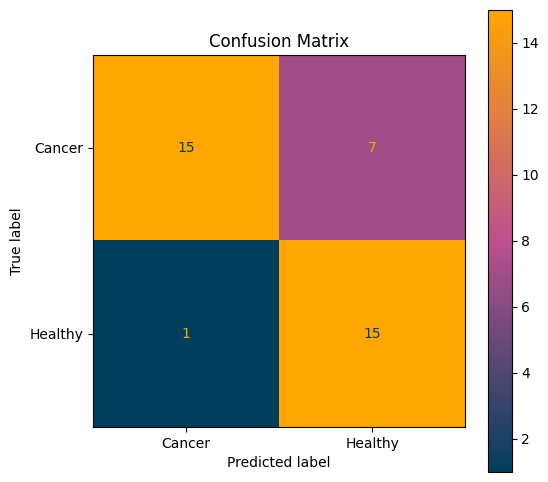

Top 5 Close skip 1
Confusion Matrix:
 [[14  8]
 [ 1 15]]
True Positives: 15
False Positives: 8
True Negatives: 14
False Negatives: 1

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.93      0.64      0.76        22
     Healthy       0.65      0.94      0.77        16

    accuracy                           0.76        38
   macro avg       0.79      0.79      0.76        38
weighted avg       0.81      0.76      0.76        38



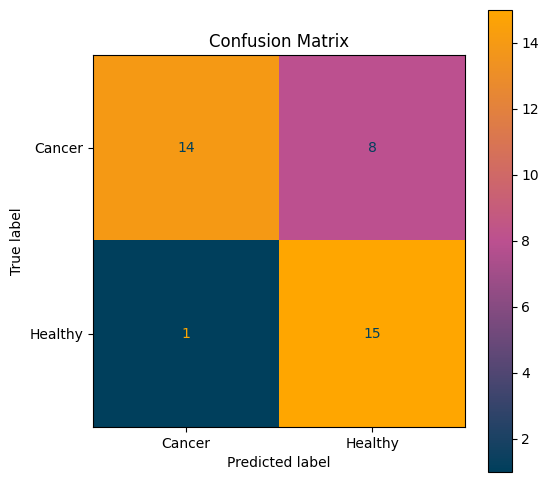

Top 12 Close skip 1
Confusion Matrix:
 [[14  8]
 [ 1 15]]
True Positives: 15
False Positives: 8
True Negatives: 14
False Negatives: 1

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.93      0.64      0.76        22
     Healthy       0.65      0.94      0.77        16

    accuracy                           0.76        38
   macro avg       0.79      0.79      0.76        38
weighted avg       0.81      0.76      0.76        38



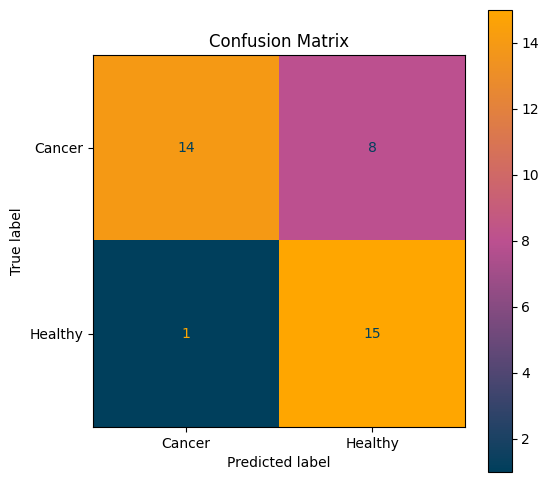

All Close skip 1
Confusion Matrix:
 [[13  9]
 [ 1 15]]
True Positives: 15
False Positives: 9
True Negatives: 13
False Negatives: 1

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.93      0.59      0.72        22
     Healthy       0.62      0.94      0.75        16

    accuracy                           0.74        38
   macro avg       0.78      0.76      0.74        38
weighted avg       0.80      0.74      0.73        38



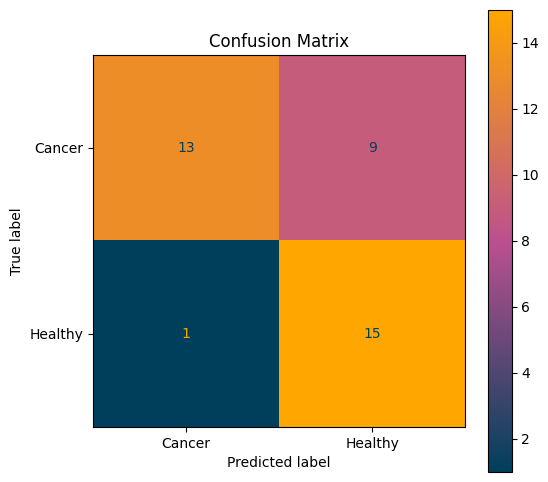

Top 2 All
Confusion Matrix:
 [[16  6]
 [ 1 15]]
True Positives: 15
False Positives: 6
True Negatives: 16
False Negatives: 1

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.94      0.73      0.82        22
     Healthy       0.71      0.94      0.81        16

    accuracy                           0.82        38
   macro avg       0.83      0.83      0.82        38
weighted avg       0.85      0.82      0.82        38



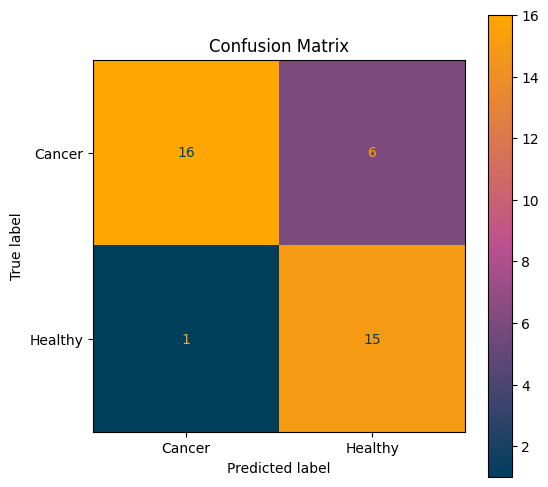

Top 3 All
Confusion Matrix:
 [[16  6]
 [ 1 15]]
True Positives: 15
False Positives: 6
True Negatives: 16
False Negatives: 1

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.94      0.73      0.82        22
     Healthy       0.71      0.94      0.81        16

    accuracy                           0.82        38
   macro avg       0.83      0.83      0.82        38
weighted avg       0.85      0.82      0.82        38



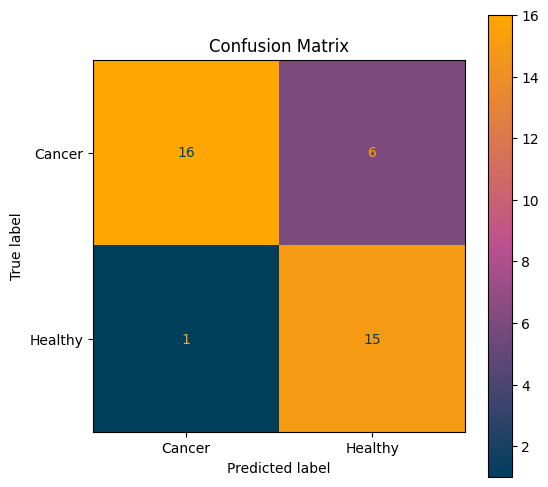

Top 5 All
Confusion Matrix:
 [[17  5]
 [ 1 15]]
True Positives: 15
False Positives: 5
True Negatives: 17
False Negatives: 1

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.94      0.77      0.85        22
     Healthy       0.75      0.94      0.83        16

    accuracy                           0.84        38
   macro avg       0.85      0.86      0.84        38
weighted avg       0.86      0.84      0.84        38



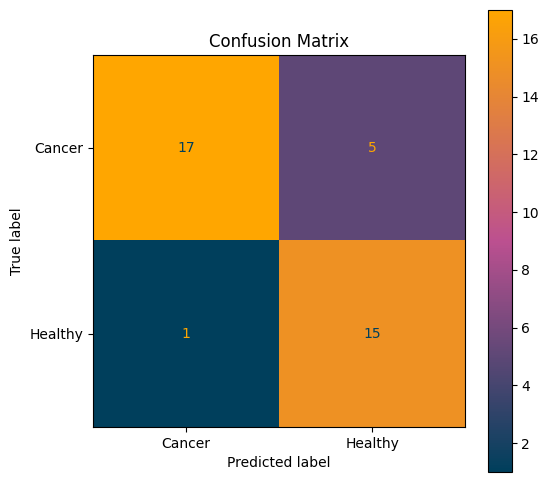

Top 12 All
Confusion Matrix:
 [[17  5]
 [ 1 15]]
True Positives: 15
False Positives: 5
True Negatives: 17
False Negatives: 1

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.94      0.77      0.85        22
     Healthy       0.75      0.94      0.83        16

    accuracy                           0.84        38
   macro avg       0.85      0.86      0.84        38
weighted avg       0.86      0.84      0.84        38



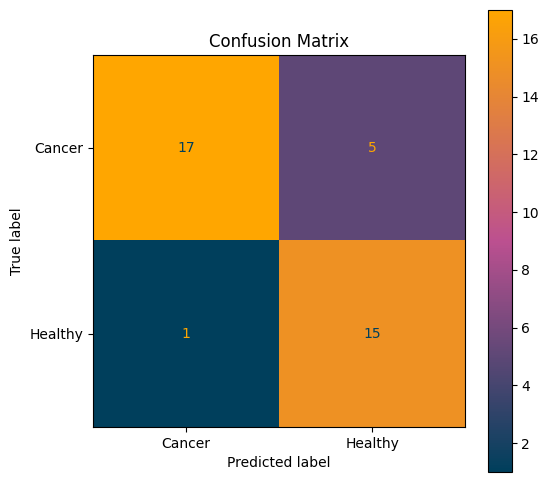

All All
Confusion Matrix:
 [[16  6]
 [ 1 15]]
True Positives: 15
False Positives: 6
True Negatives: 16
False Negatives: 1

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.94      0.73      0.82        22
     Healthy       0.71      0.94      0.81        16

    accuracy                           0.82        38
   macro avg       0.83      0.83      0.82        38
weighted avg       0.85      0.82      0.82        38



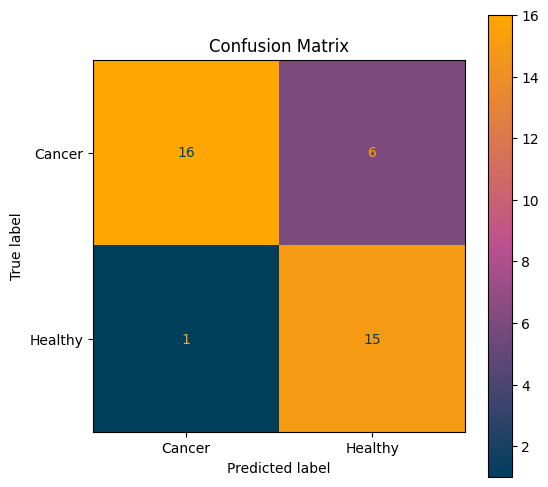

Train patients: [ 0  2  3  4  6  7  8  9 10 13 14 16 18 19 20 22 23 24 27 28 29 30 31 33
 36 37 39 40 41 42 43 44 45 46 47 48 49 50 51 53 54 56 57 58 59 61 62 63
 64 65 66 67 68 69 70 73 74 76 77 78 80 81 82 83 85 86 87 88 89 90 91 92
 94 95 97 99]
Test patients: [12 38 25 55 11 34 75 60 79  1 35 84 15 72 21 32 52 96]

Fold 4: 83.9% train / 16.1% test
Fold 4: 83.9% train / 16.1% test
  Training: 151 samples from 76 patients
  Testing:  29 samples from 18 patients
Top 2 Long a+
Confusion Matrix:
 [[10  1]
 [ 6 12]]
True Positives: 12
False Positives: 1
True Negatives: 10
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.62      0.91      0.74        11
     Healthy       0.92      0.67      0.77        18

    accuracy                           0.76        29
   macro avg       0.77      0.79      0.76        29
weighted avg       0.81      0.76      0.76        29



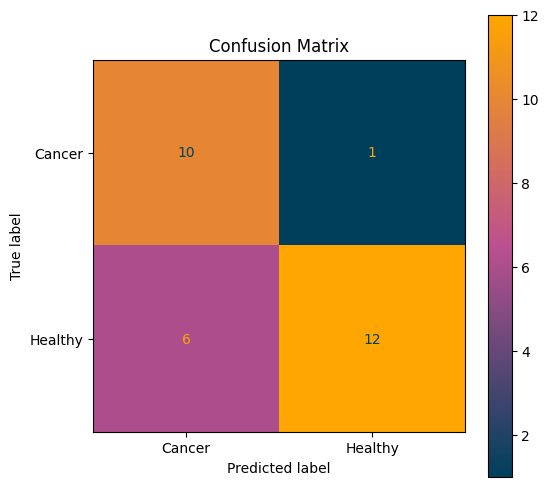

Top 3 Long a+
Confusion Matrix:
 [[10  1]
 [ 4 14]]
True Positives: 14
False Positives: 1
True Negatives: 10
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.71      0.91      0.80        11
     Healthy       0.93      0.78      0.85        18

    accuracy                           0.83        29
   macro avg       0.82      0.84      0.82        29
weighted avg       0.85      0.83      0.83        29



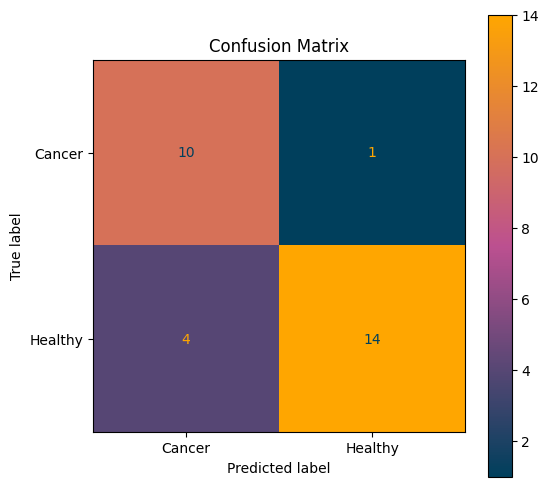

Top 5 Long a+
Confusion Matrix:
 [[10  1]
 [ 4 14]]
True Positives: 14
False Positives: 1
True Negatives: 10
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.71      0.91      0.80        11
     Healthy       0.93      0.78      0.85        18

    accuracy                           0.83        29
   macro avg       0.82      0.84      0.82        29
weighted avg       0.85      0.83      0.83        29



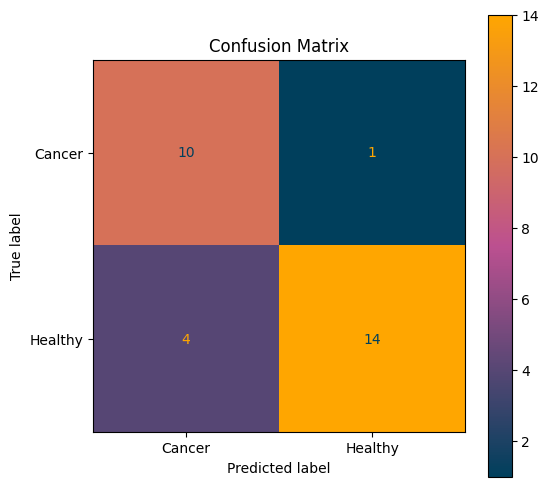

Top 12 Long a+
Confusion Matrix:
 [[11  0]
 [ 4 14]]
True Positives: 14
False Positives: 0
True Negatives: 11
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.73      1.00      0.85        11
     Healthy       1.00      0.78      0.88        18

    accuracy                           0.86        29
   macro avg       0.87      0.89      0.86        29
weighted avg       0.90      0.86      0.86        29



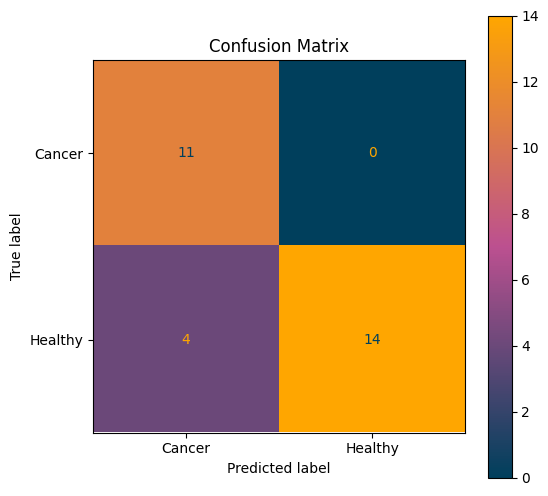

All Long a+
Confusion Matrix:
 [[11  0]
 [ 4 14]]
True Positives: 14
False Positives: 0
True Negatives: 11
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.73      1.00      0.85        11
     Healthy       1.00      0.78      0.88        18

    accuracy                           0.86        29
   macro avg       0.87      0.89      0.86        29
weighted avg       0.90      0.86      0.86        29



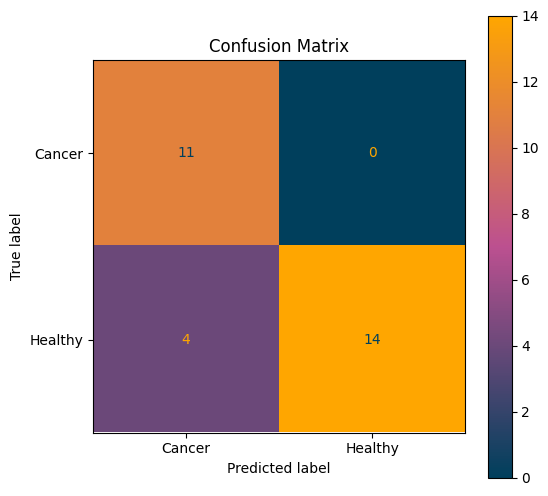

Top 2 Long a+ ext.
Confusion Matrix:
 [[ 7  4]
 [ 3 15]]
True Positives: 15
False Positives: 4
True Negatives: 7
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.70      0.64      0.67        11
     Healthy       0.79      0.83      0.81        18

    accuracy                           0.76        29
   macro avg       0.74      0.73      0.74        29
weighted avg       0.76      0.76      0.76        29



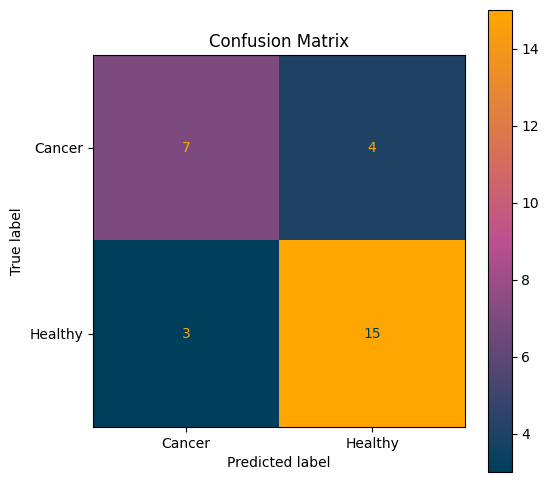

Top 3 Long a+ ext.
Confusion Matrix:
 [[ 7  4]
 [ 3 15]]
True Positives: 15
False Positives: 4
True Negatives: 7
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.70      0.64      0.67        11
     Healthy       0.79      0.83      0.81        18

    accuracy                           0.76        29
   macro avg       0.74      0.73      0.74        29
weighted avg       0.76      0.76      0.76        29



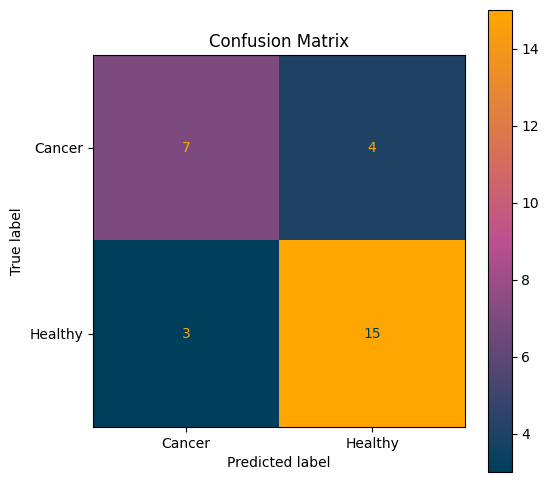

Top 5 Long a+ ext.
Confusion Matrix:
 [[ 7  4]
 [ 3 15]]
True Positives: 15
False Positives: 4
True Negatives: 7
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.70      0.64      0.67        11
     Healthy       0.79      0.83      0.81        18

    accuracy                           0.76        29
   macro avg       0.74      0.73      0.74        29
weighted avg       0.76      0.76      0.76        29



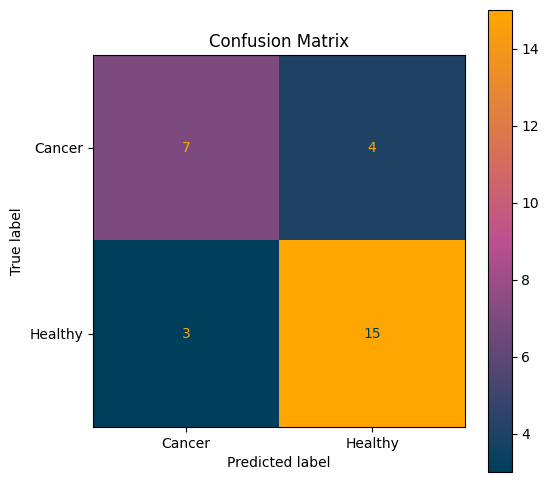

Top 12 Long a+ ext.
Confusion Matrix:
 [[ 9  2]
 [ 3 15]]
True Positives: 15
False Positives: 2
True Negatives: 9
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.75      0.82      0.78        11
     Healthy       0.88      0.83      0.86        18

    accuracy                           0.83        29
   macro avg       0.82      0.83      0.82        29
weighted avg       0.83      0.83      0.83        29



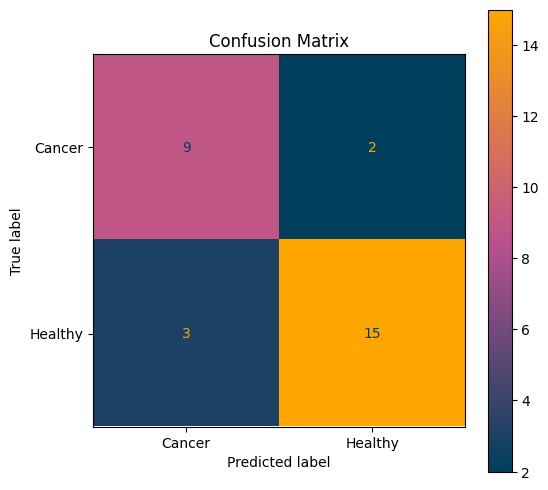

All Long a+ ext.
Confusion Matrix:
 [[ 9  2]
 [ 2 16]]
True Positives: 16
False Positives: 2
True Negatives: 9
False Negatives: 2

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.82      0.82      0.82        11
     Healthy       0.89      0.89      0.89        18

    accuracy                           0.86        29
   macro avg       0.85      0.85      0.85        29
weighted avg       0.86      0.86      0.86        29



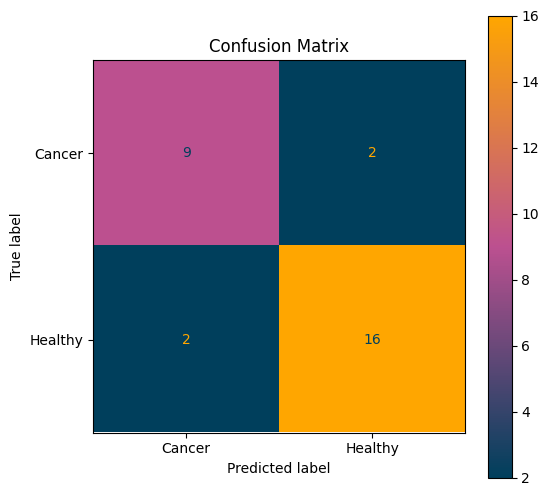

Top 2 Med. a+ ext.
Confusion Matrix:
 [[ 9  2]
 [ 6 12]]
True Positives: 12
False Positives: 2
True Negatives: 9
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.60      0.82      0.69        11
     Healthy       0.86      0.67      0.75        18

    accuracy                           0.72        29
   macro avg       0.73      0.74      0.72        29
weighted avg       0.76      0.72      0.73        29



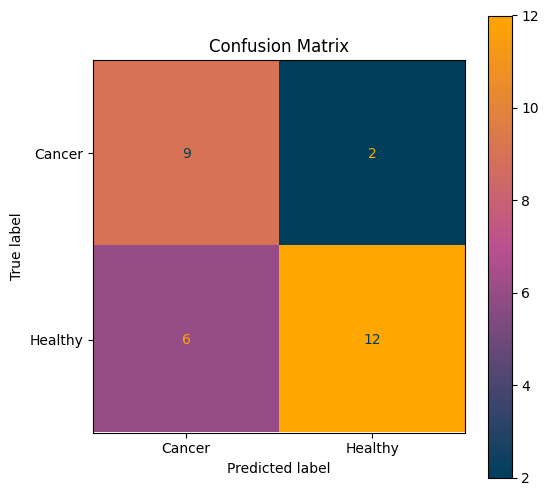

Top 3 Med. a+ ext.
Confusion Matrix:
 [[ 9  2]
 [ 5 13]]
True Positives: 13
False Positives: 2
True Negatives: 9
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.64      0.82      0.72        11
     Healthy       0.87      0.72      0.79        18

    accuracy                           0.76        29
   macro avg       0.75      0.77      0.75        29
weighted avg       0.78      0.76      0.76        29



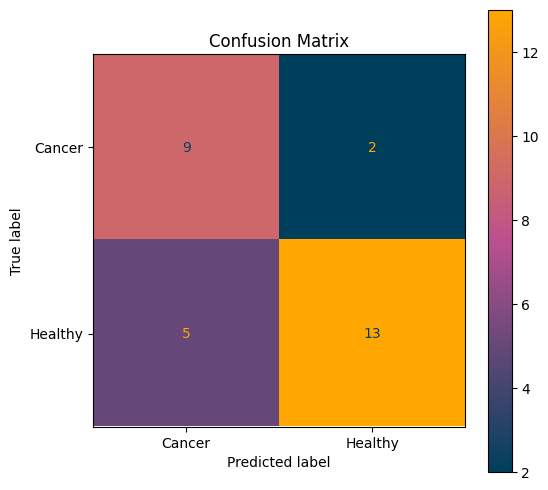

Top 5 Med. a+ ext.
Confusion Matrix:
 [[ 9  2]
 [ 6 12]]
True Positives: 12
False Positives: 2
True Negatives: 9
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.60      0.82      0.69        11
     Healthy       0.86      0.67      0.75        18

    accuracy                           0.72        29
   macro avg       0.73      0.74      0.72        29
weighted avg       0.76      0.72      0.73        29



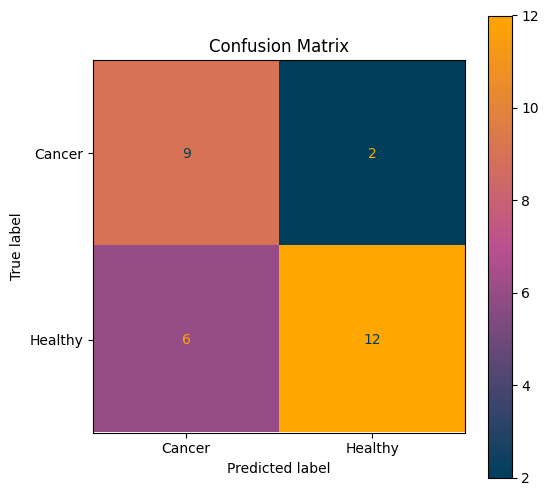

Top 12 Med. a+ ext.
Confusion Matrix:
 [[ 8  3]
 [ 6 12]]
True Positives: 12
False Positives: 3
True Negatives: 8
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.57      0.73      0.64        11
     Healthy       0.80      0.67      0.73        18

    accuracy                           0.69        29
   macro avg       0.69      0.70      0.68        29
weighted avg       0.71      0.69      0.69        29



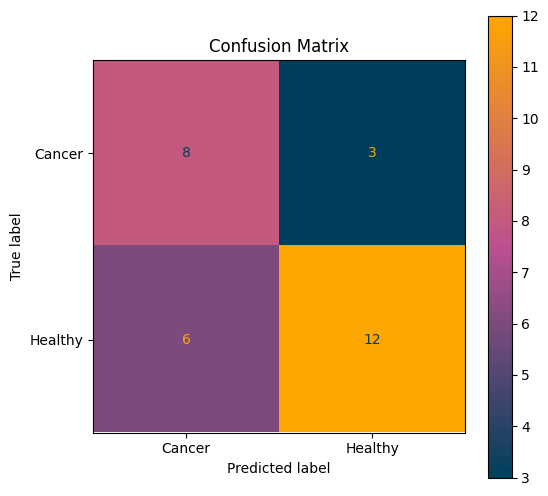

All Med. a+ ext.
Confusion Matrix:
 [[ 9  2]
 [ 5 13]]
True Positives: 13
False Positives: 2
True Negatives: 9
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.64      0.82      0.72        11
     Healthy       0.87      0.72      0.79        18

    accuracy                           0.76        29
   macro avg       0.75      0.77      0.75        29
weighted avg       0.78      0.76      0.76        29



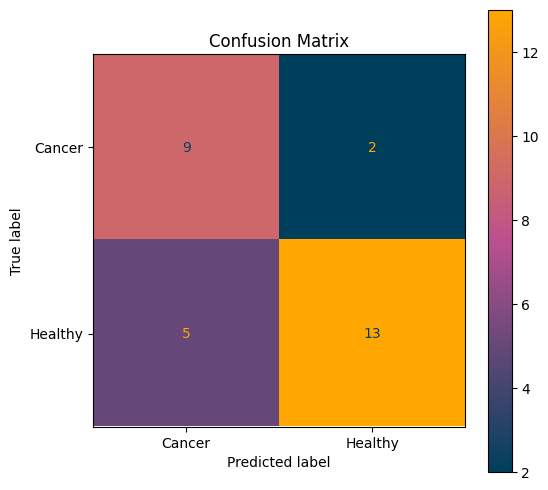

Top 2 Close skip 1
Confusion Matrix:
 [[10  1]
 [ 5 13]]
True Positives: 13
False Positives: 1
True Negatives: 10
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.67      0.91      0.77        11
     Healthy       0.93      0.72      0.81        18

    accuracy                           0.79        29
   macro avg       0.80      0.82      0.79        29
weighted avg       0.83      0.79      0.80        29



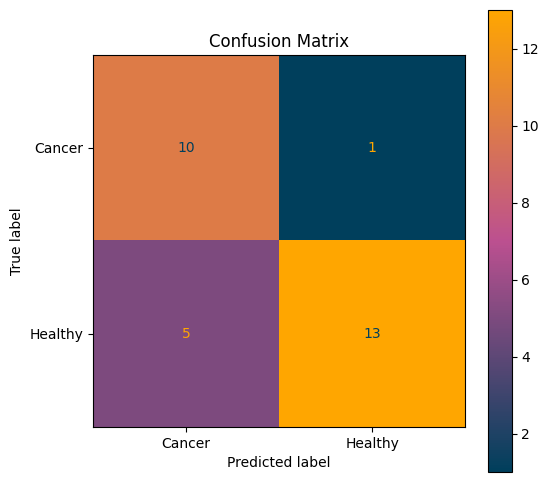

Top 3 Close skip 1
Confusion Matrix:
 [[ 8  3]
 [ 6 12]]
True Positives: 12
False Positives: 3
True Negatives: 8
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.57      0.73      0.64        11
     Healthy       0.80      0.67      0.73        18

    accuracy                           0.69        29
   macro avg       0.69      0.70      0.68        29
weighted avg       0.71      0.69      0.69        29



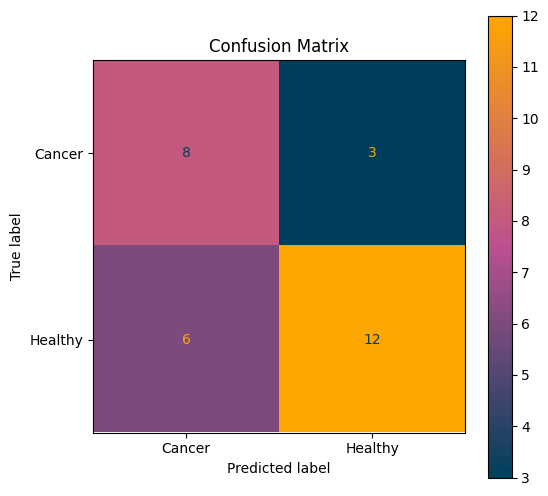

Top 5 Close skip 1
Confusion Matrix:
 [[ 8  3]
 [ 5 13]]
True Positives: 13
False Positives: 3
True Negatives: 8
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.62      0.73      0.67        11
     Healthy       0.81      0.72      0.76        18

    accuracy                           0.72        29
   macro avg       0.71      0.72      0.72        29
weighted avg       0.74      0.72      0.73        29



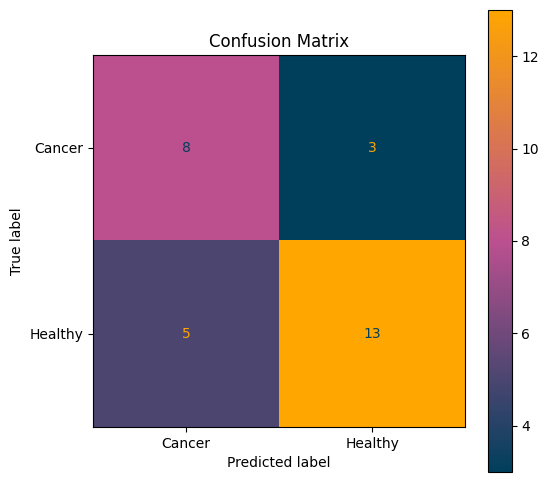

Top 12 Close skip 1
Confusion Matrix:
 [[ 8  3]
 [ 5 13]]
True Positives: 13
False Positives: 3
True Negatives: 8
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.62      0.73      0.67        11
     Healthy       0.81      0.72      0.76        18

    accuracy                           0.72        29
   macro avg       0.71      0.72      0.72        29
weighted avg       0.74      0.72      0.73        29



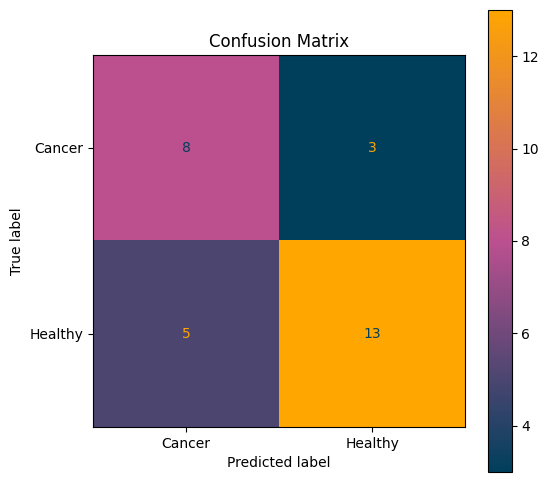

All Close skip 1
Confusion Matrix:
 [[ 8  3]
 [ 4 14]]
True Positives: 14
False Positives: 3
True Negatives: 8
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.67      0.73      0.70        11
     Healthy       0.82      0.78      0.80        18

    accuracy                           0.76        29
   macro avg       0.75      0.75      0.75        29
weighted avg       0.76      0.76      0.76        29



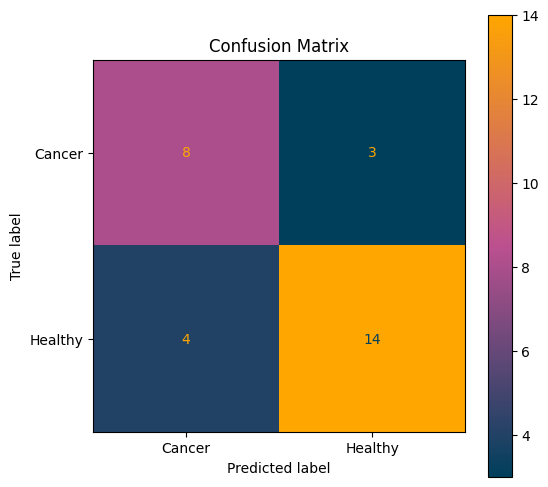

Top 2 All
Confusion Matrix:
 [[ 9  2]
 [ 3 15]]
True Positives: 15
False Positives: 2
True Negatives: 9
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.75      0.82      0.78        11
     Healthy       0.88      0.83      0.86        18

    accuracy                           0.83        29
   macro avg       0.82      0.83      0.82        29
weighted avg       0.83      0.83      0.83        29



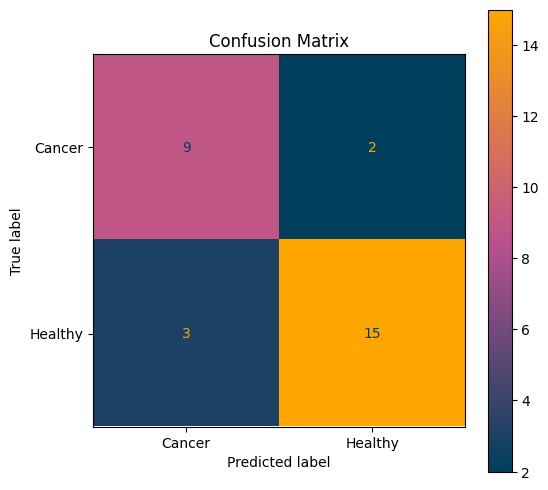

Top 3 All
Confusion Matrix:
 [[10  1]
 [ 4 14]]
True Positives: 14
False Positives: 1
True Negatives: 10
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.71      0.91      0.80        11
     Healthy       0.93      0.78      0.85        18

    accuracy                           0.83        29
   macro avg       0.82      0.84      0.82        29
weighted avg       0.85      0.83      0.83        29



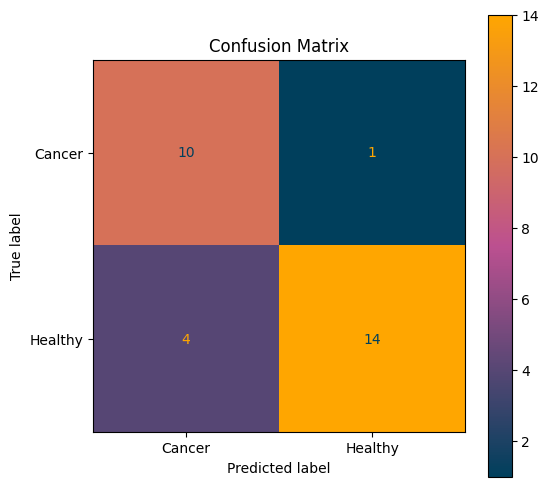

Top 5 All
Confusion Matrix:
 [[10  1]
 [ 3 15]]
True Positives: 15
False Positives: 1
True Negatives: 10
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.77      0.91      0.83        11
     Healthy       0.94      0.83      0.88        18

    accuracy                           0.86        29
   macro avg       0.85      0.87      0.86        29
weighted avg       0.87      0.86      0.86        29



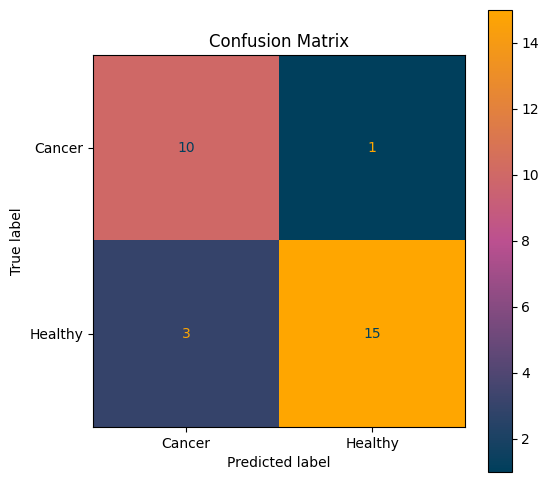

Top 12 All
Confusion Matrix:
 [[10  1]
 [ 4 14]]
True Positives: 14
False Positives: 1
True Negatives: 10
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.71      0.91      0.80        11
     Healthy       0.93      0.78      0.85        18

    accuracy                           0.83        29
   macro avg       0.82      0.84      0.82        29
weighted avg       0.85      0.83      0.83        29



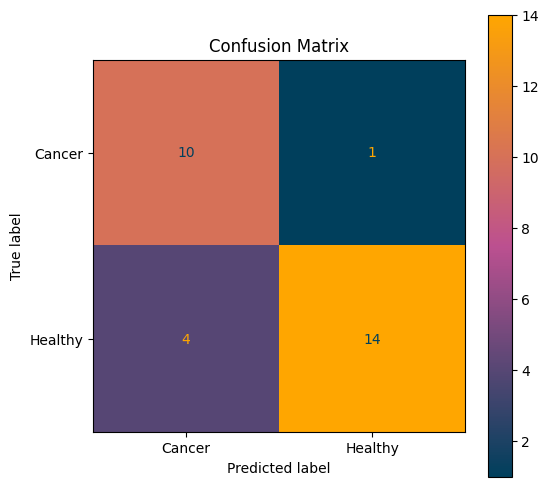

All All
Confusion Matrix:
 [[ 9  2]
 [ 4 14]]
True Positives: 14
False Positives: 2
True Negatives: 9
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.69      0.82      0.75        11
     Healthy       0.88      0.78      0.82        18

    accuracy                           0.79        29
   macro avg       0.78      0.80      0.79        29
weighted avg       0.81      0.79      0.80        29



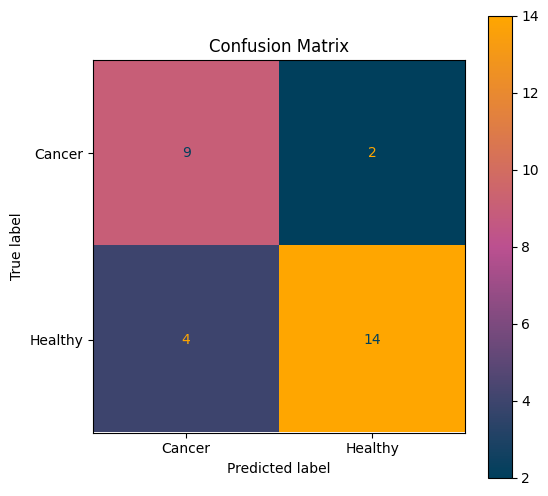

Train patients: [ 0  1  2  3  4  6  7  8  9 11 12 14 15 16 18 19 20 21 24 25 27 29 30 31
 32 33 34 35 36 37 38 41 43 44 45 46 48 51 52 53 54 55 56 57 58 59 60 62
 63 64 65 66 69 72 75 77 78 79 80 81 82 83 84 85 86 88 89 90 91 94 96 99]
Test patients: [97 73 22 92 76 28 40 49 42 68 61 13 74 39 23 87 10 95 70 67 50 47]

Fold 5: 78.9% train / 21.1% test
Fold 5: 78.9% train / 21.1% test
  Training: 142 samples from 72 patients
  Testing:  38 samples from 22 patients
Top 2 Long a+
Confusion Matrix:
 [[16  2]
 [13  7]]
True Positives: 7
False Positives: 2
True Negatives: 16
False Negatives: 13

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.55      0.89      0.68        18
     Healthy       0.78      0.35      0.48        20

    accuracy                           0.61        38
   macro avg       0.66      0.62      0.58        38
weighted avg       0.67      0.61      0.58        38



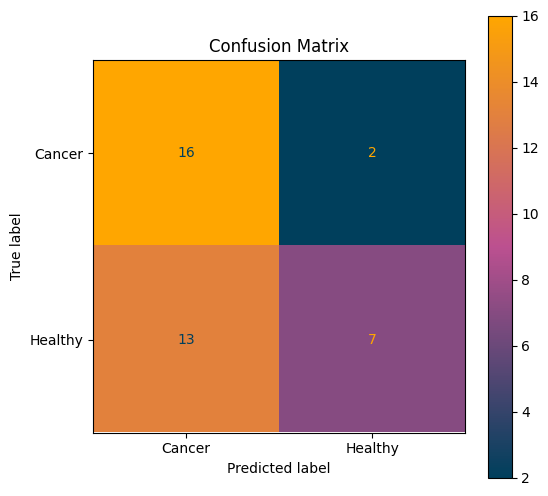

Top 3 Long a+
Confusion Matrix:
 [[17  1]
 [11  9]]
True Positives: 9
False Positives: 1
True Negatives: 17
False Negatives: 11

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.61      0.94      0.74        18
     Healthy       0.90      0.45      0.60        20

    accuracy                           0.68        38
   macro avg       0.75      0.70      0.67        38
weighted avg       0.76      0.68      0.67        38



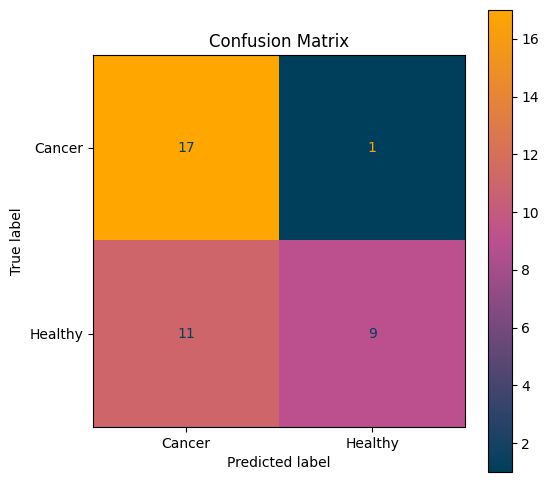

Top 5 Long a+
Confusion Matrix:
 [[17  1]
 [ 9 11]]
True Positives: 11
False Positives: 1
True Negatives: 17
False Negatives: 9

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.65      0.94      0.77        18
     Healthy       0.92      0.55      0.69        20

    accuracy                           0.74        38
   macro avg       0.79      0.75      0.73        38
weighted avg       0.79      0.74      0.73        38



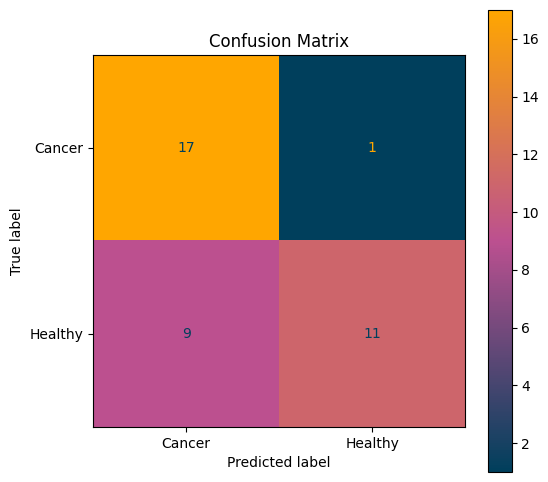

Top 12 Long a+
Confusion Matrix:
 [[16  2]
 [ 9 11]]
True Positives: 11
False Positives: 2
True Negatives: 16
False Negatives: 9

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.64      0.89      0.74        18
     Healthy       0.85      0.55      0.67        20

    accuracy                           0.71        38
   macro avg       0.74      0.72      0.71        38
weighted avg       0.75      0.71      0.70        38



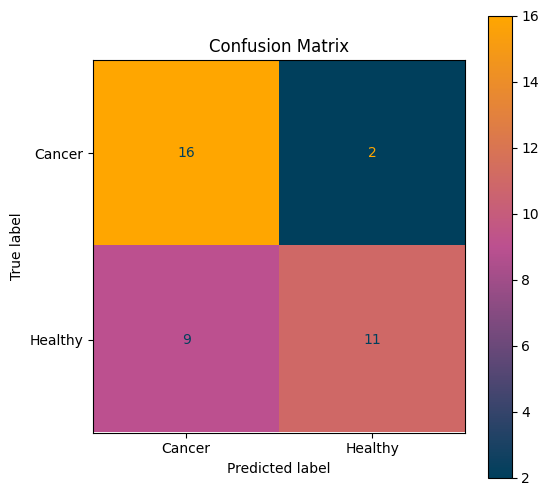

All Long a+
Confusion Matrix:
 [[16  2]
 [ 9 11]]
True Positives: 11
False Positives: 2
True Negatives: 16
False Negatives: 9

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.64      0.89      0.74        18
     Healthy       0.85      0.55      0.67        20

    accuracy                           0.71        38
   macro avg       0.74      0.72      0.71        38
weighted avg       0.75      0.71      0.70        38



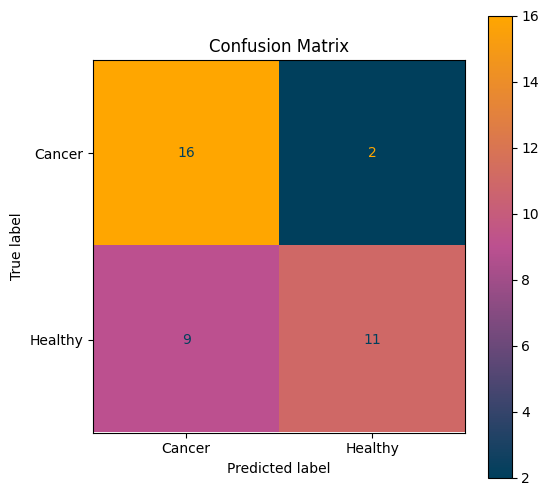

Top 2 Long a+ ext.
Confusion Matrix:
 [[15  3]
 [11  9]]
True Positives: 9
False Positives: 3
True Negatives: 15
False Negatives: 11

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.58      0.83      0.68        18
     Healthy       0.75      0.45      0.56        20

    accuracy                           0.63        38
   macro avg       0.66      0.64      0.62        38
weighted avg       0.67      0.63      0.62        38



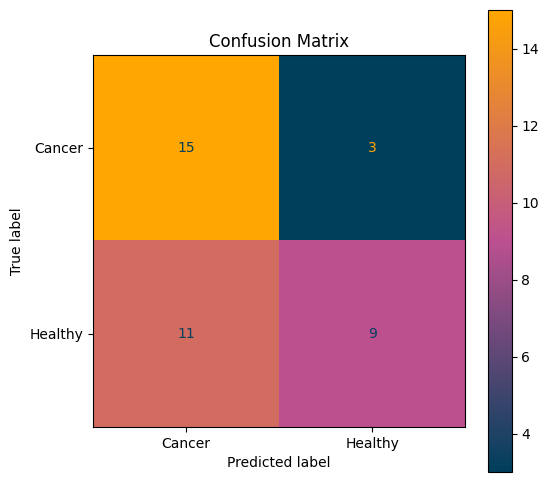

Top 3 Long a+ ext.
Confusion Matrix:
 [[17  1]
 [ 7 13]]
True Positives: 13
False Positives: 1
True Negatives: 17
False Negatives: 7

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.71      0.94      0.81        18
     Healthy       0.93      0.65      0.76        20

    accuracy                           0.79        38
   macro avg       0.82      0.80      0.79        38
weighted avg       0.82      0.79      0.79        38



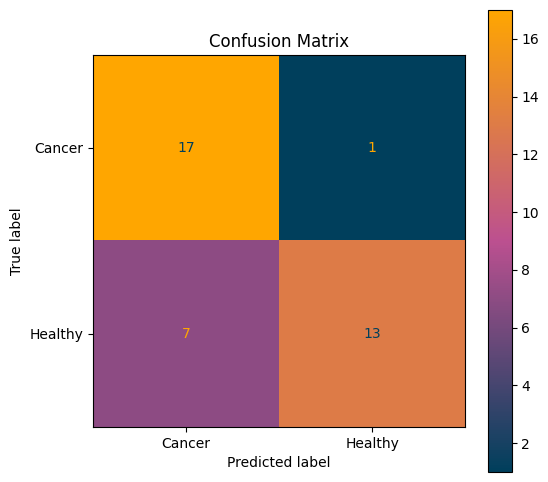

Top 5 Long a+ ext.
Confusion Matrix:
 [[16  2]
 [ 3 17]]
True Positives: 17
False Positives: 2
True Negatives: 16
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.84      0.89      0.86        18
     Healthy       0.89      0.85      0.87        20

    accuracy                           0.87        38
   macro avg       0.87      0.87      0.87        38
weighted avg       0.87      0.87      0.87        38



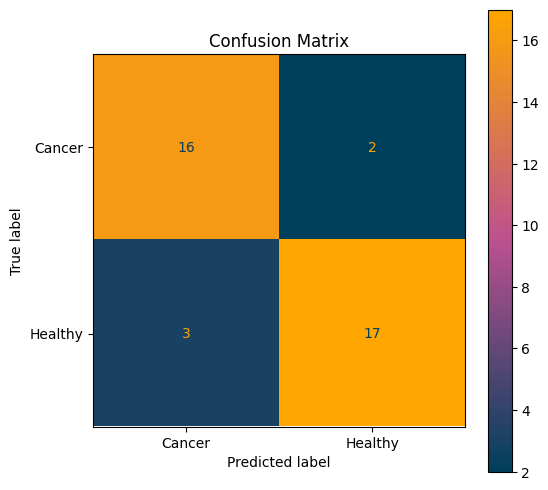

Top 12 Long a+ ext.
Confusion Matrix:
 [[16  2]
 [ 6 14]]
True Positives: 14
False Positives: 2
True Negatives: 16
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.73      0.89      0.80        18
     Healthy       0.88      0.70      0.78        20

    accuracy                           0.79        38
   macro avg       0.80      0.79      0.79        38
weighted avg       0.81      0.79      0.79        38



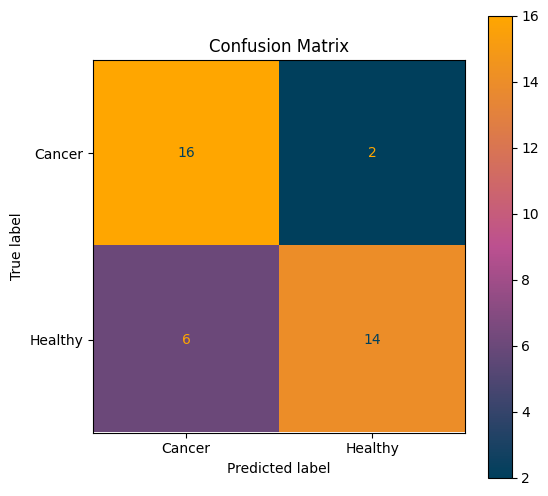

All Long a+ ext.
Confusion Matrix:
 [[17  1]
 [ 8 12]]
True Positives: 12
False Positives: 1
True Negatives: 17
False Negatives: 8

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.68      0.94      0.79        18
     Healthy       0.92      0.60      0.73        20

    accuracy                           0.76        38
   macro avg       0.80      0.77      0.76        38
weighted avg       0.81      0.76      0.76        38



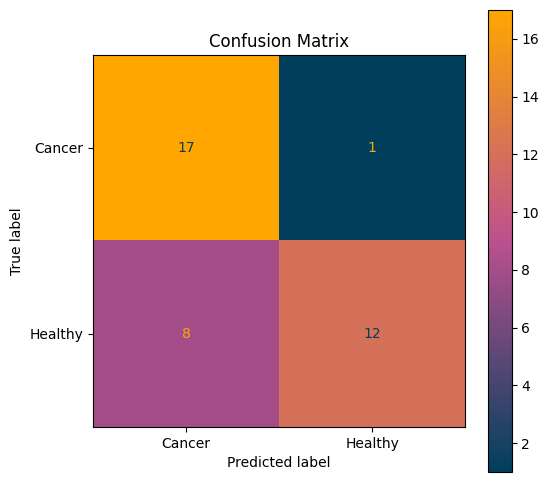

Top 2 Med. a+ ext.
Confusion Matrix:
 [[14  4]
 [ 7 13]]
True Positives: 13
False Positives: 4
True Negatives: 14
False Negatives: 7

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.67      0.78      0.72        18
     Healthy       0.76      0.65      0.70        20

    accuracy                           0.71        38
   macro avg       0.72      0.71      0.71        38
weighted avg       0.72      0.71      0.71        38



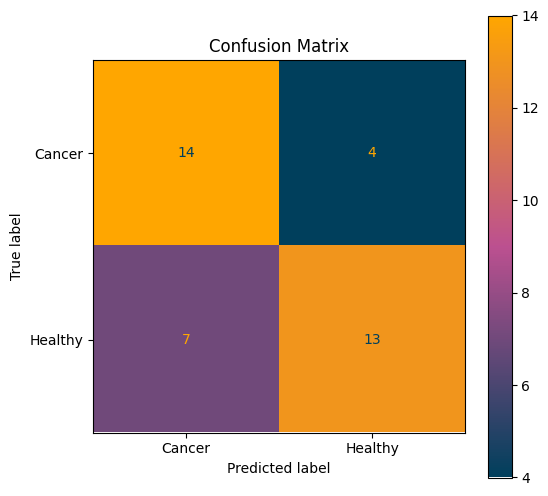

Top 3 Med. a+ ext.
Confusion Matrix:
 [[15  3]
 [ 9 11]]
True Positives: 11
False Positives: 3
True Negatives: 15
False Negatives: 9

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.62      0.83      0.71        18
     Healthy       0.79      0.55      0.65        20

    accuracy                           0.68        38
   macro avg       0.71      0.69      0.68        38
weighted avg       0.71      0.68      0.68        38



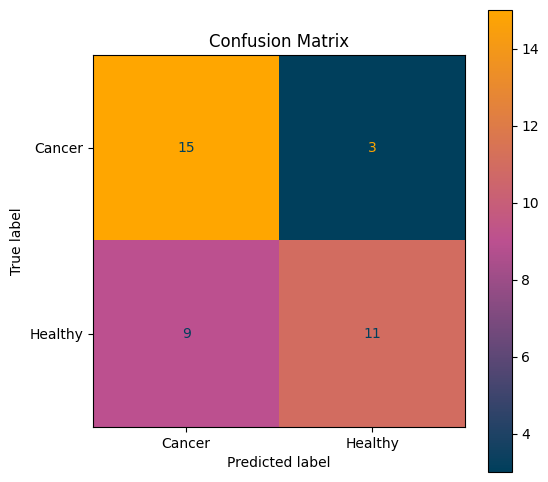

Top 5 Med. a+ ext.
Confusion Matrix:
 [[16  2]
 [ 8 12]]
True Positives: 12
False Positives: 2
True Negatives: 16
False Negatives: 8

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.67      0.89      0.76        18
     Healthy       0.86      0.60      0.71        20

    accuracy                           0.74        38
   macro avg       0.76      0.74      0.73        38
weighted avg       0.77      0.74      0.73        38



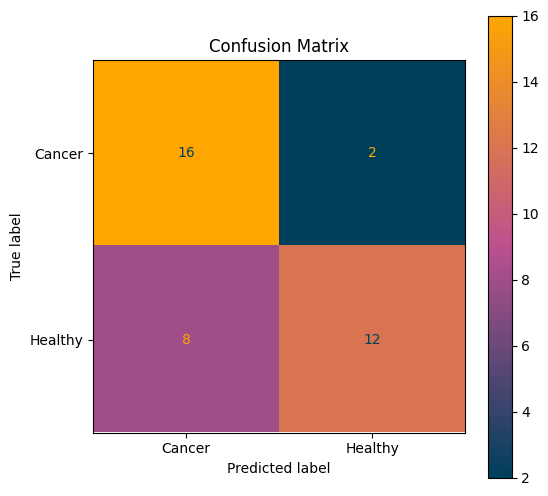

Top 12 Med. a+ ext.
Confusion Matrix:
 [[16  2]
 [ 4 16]]
True Positives: 16
False Positives: 2
True Negatives: 16
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.80      0.89      0.84        18
     Healthy       0.89      0.80      0.84        20

    accuracy                           0.84        38
   macro avg       0.84      0.84      0.84        38
weighted avg       0.85      0.84      0.84        38



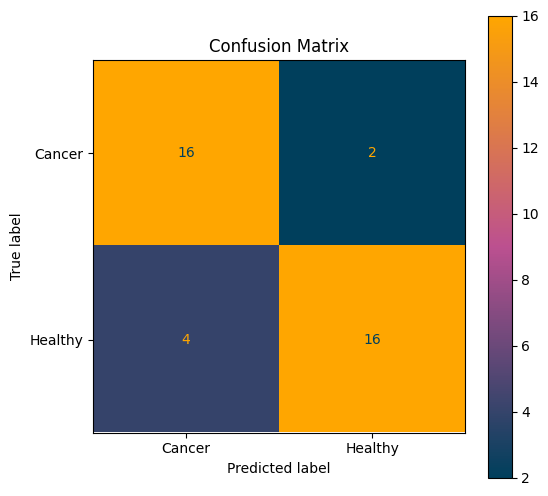

All Med. a+ ext.
Confusion Matrix:
 [[16  2]
 [ 4 16]]
True Positives: 16
False Positives: 2
True Negatives: 16
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.80      0.89      0.84        18
     Healthy       0.89      0.80      0.84        20

    accuracy                           0.84        38
   macro avg       0.84      0.84      0.84        38
weighted avg       0.85      0.84      0.84        38



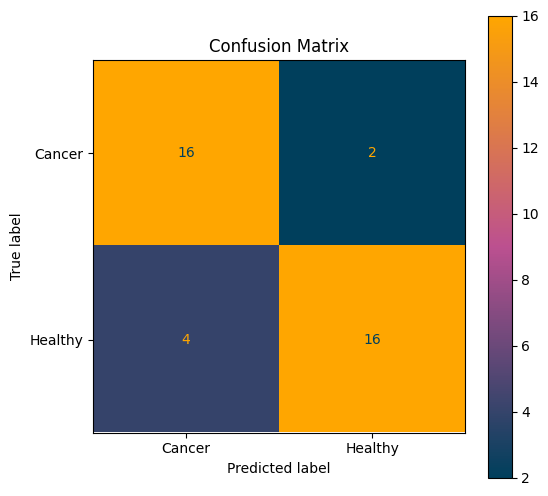

Top 2 Close skip 1
Confusion Matrix:
 [[14  4]
 [ 9 11]]
True Positives: 11
False Positives: 4
True Negatives: 14
False Negatives: 9

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.61      0.78      0.68        18
     Healthy       0.73      0.55      0.63        20

    accuracy                           0.66        38
   macro avg       0.67      0.66      0.66        38
weighted avg       0.67      0.66      0.65        38



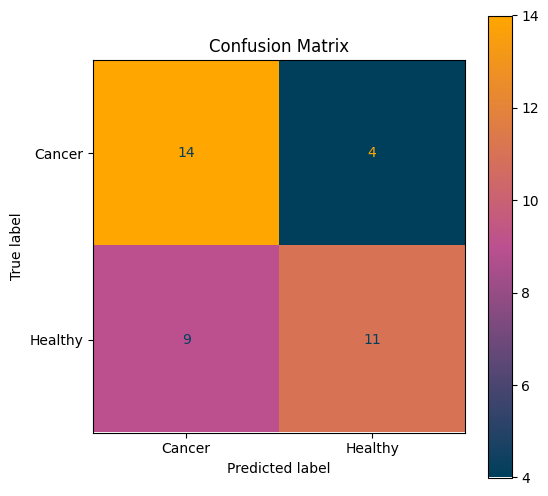

Top 3 Close skip 1
Confusion Matrix:
 [[15  3]
 [ 8 12]]
True Positives: 12
False Positives: 3
True Negatives: 15
False Negatives: 8

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.65      0.83      0.73        18
     Healthy       0.80      0.60      0.69        20

    accuracy                           0.71        38
   macro avg       0.73      0.72      0.71        38
weighted avg       0.73      0.71      0.71        38



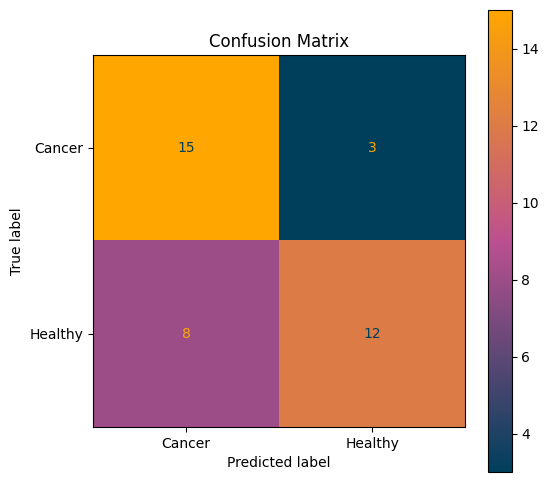

Top 5 Close skip 1
Confusion Matrix:
 [[15  3]
 [ 8 12]]
True Positives: 12
False Positives: 3
True Negatives: 15
False Negatives: 8

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.65      0.83      0.73        18
     Healthy       0.80      0.60      0.69        20

    accuracy                           0.71        38
   macro avg       0.73      0.72      0.71        38
weighted avg       0.73      0.71      0.71        38



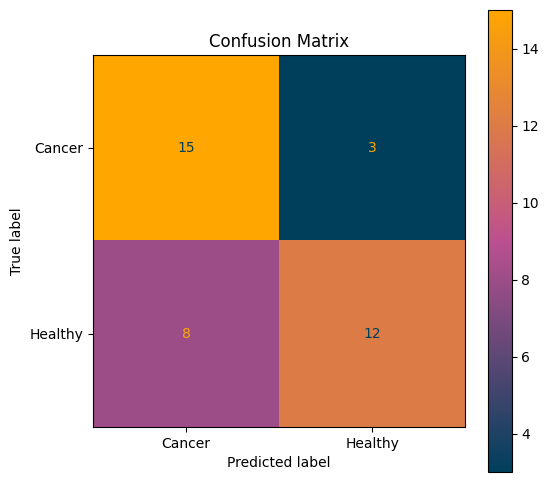

Top 12 Close skip 1
Confusion Matrix:
 [[15  3]
 [ 6 14]]
True Positives: 14
False Positives: 3
True Negatives: 15
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.71      0.83      0.77        18
     Healthy       0.82      0.70      0.76        20

    accuracy                           0.76        38
   macro avg       0.77      0.77      0.76        38
weighted avg       0.77      0.76      0.76        38



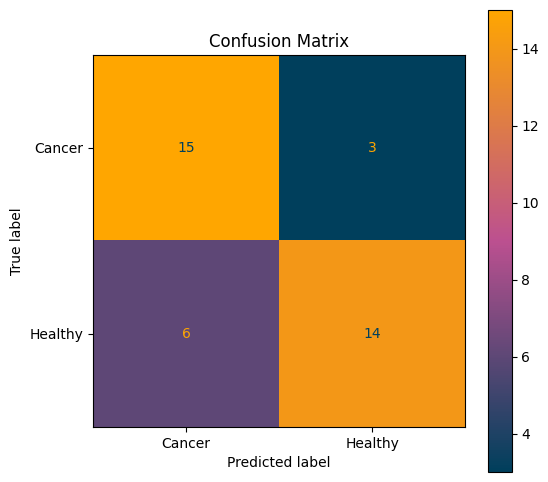

All Close skip 1
Confusion Matrix:
 [[14  4]
 [ 6 14]]
True Positives: 14
False Positives: 4
True Negatives: 14
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.70      0.78      0.74        18
     Healthy       0.78      0.70      0.74        20

    accuracy                           0.74        38
   macro avg       0.74      0.74      0.74        38
weighted avg       0.74      0.74      0.74        38



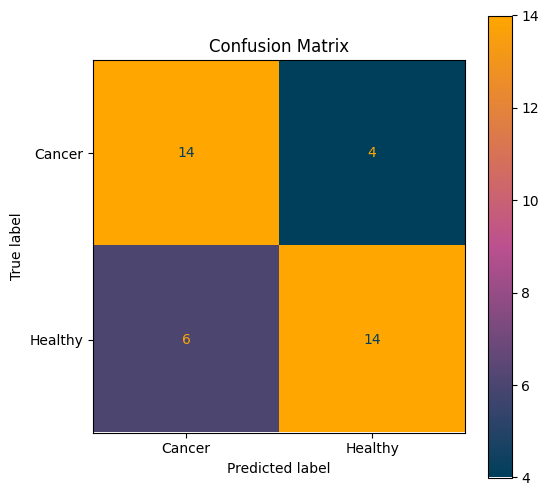

Top 2 All
Confusion Matrix:
 [[15  3]
 [ 6 14]]
True Positives: 14
False Positives: 3
True Negatives: 15
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.71      0.83      0.77        18
     Healthy       0.82      0.70      0.76        20

    accuracy                           0.76        38
   macro avg       0.77      0.77      0.76        38
weighted avg       0.77      0.76      0.76        38



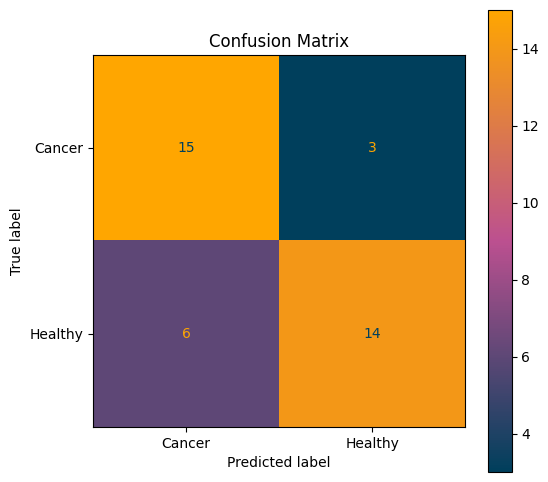

Top 3 All
Confusion Matrix:
 [[15  3]
 [ 3 17]]
True Positives: 17
False Positives: 3
True Negatives: 15
False Negatives: 3

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.83      0.83      0.83        18
     Healthy       0.85      0.85      0.85        20

    accuracy                           0.84        38
   macro avg       0.84      0.84      0.84        38
weighted avg       0.84      0.84      0.84        38



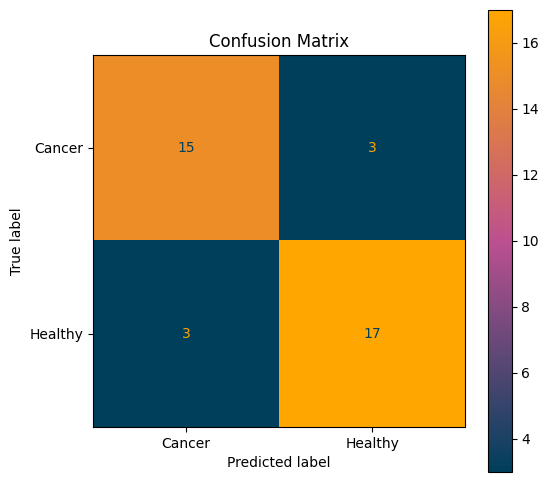

Top 5 All
Confusion Matrix:
 [[15  3]
 [ 4 16]]
True Positives: 16
False Positives: 3
True Negatives: 15
False Negatives: 4

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.79      0.83      0.81        18
     Healthy       0.84      0.80      0.82        20

    accuracy                           0.82        38
   macro avg       0.82      0.82      0.82        38
weighted avg       0.82      0.82      0.82        38



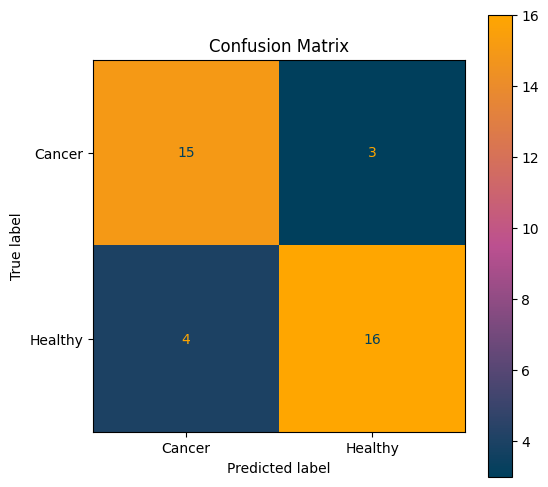

Top 12 All
Confusion Matrix:
 [[15  3]
 [ 5 15]]
True Positives: 15
False Positives: 3
True Negatives: 15
False Negatives: 5

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.75      0.83      0.79        18
     Healthy       0.83      0.75      0.79        20

    accuracy                           0.79        38
   macro avg       0.79      0.79      0.79        38
weighted avg       0.79      0.79      0.79        38



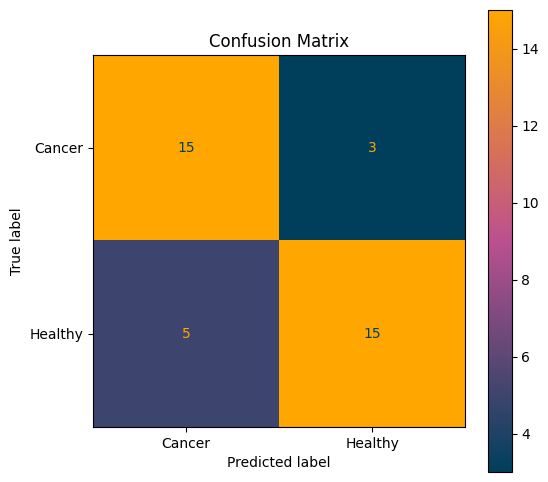

All All
Confusion Matrix:
 [[15  3]
 [ 6 14]]
True Positives: 14
False Positives: 3
True Negatives: 15
False Negatives: 6

Classification Report:

              precision    recall  f1-score   support

      Cancer       0.71      0.83      0.77        18
     Healthy       0.82      0.70      0.76        20

    accuracy                           0.76        38
   macro avg       0.77      0.77      0.76        38
weighted avg       0.77      0.76      0.76        38



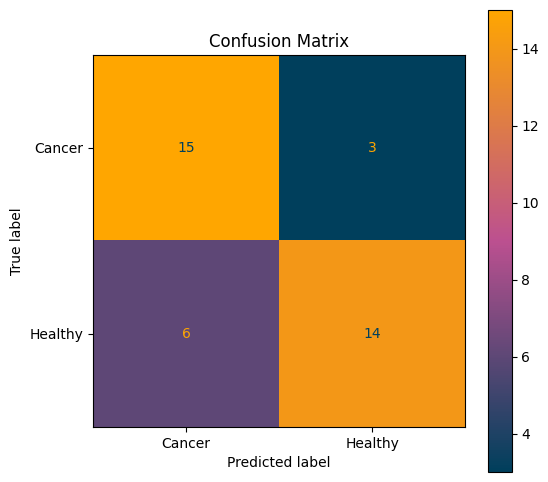

In [12]:
results_dict = {
    "Fold": [],
    "Num params.": [],
    "Mask": [],
    "Fsel": [],
    "ROC_AUC_svm": [],
}


# iterate over folds
for fold_idx, (train_patients_idx, test_patients_idx) in enumerate(folds):
    fold = fold_idx + 1

    # Get patient IDs for training and testing
    train_patients = unique_patients[train_patients_idx]
    test_patients = unique_patients[test_patients_idx]
    print("Train patients:", train_patients)
    print("Test patients:", test_patients)

    # Create masks for training and testing samples
    train_mask = np.isin(Case, train_patients)
    test_mask = np.isin(Case, test_patients)
    foldstats(train_mask, test_mask)

    # iterate over masks
    for Msel_key, Msel in zip(Mask_sel.keys(), Mask_sel.values()):
        mask.IIVV_mask(Msel, plot=False)
        # iterate over frequency selections
        for Fsel_key, Fsel in zip(Freq_sel.keys(), Freq_sel.values()):
            print(Fsel_key, Msel_key)
            X_tmp = X[:, Fsel, :]
            X_tmp = X_tmp[:, :, mask.mask]

            X_train = X_tmp[train_mask, ...]
            X_test = X_tmp[test_mask, ...]
            Y_train = Y[train_mask, ...]
            Y_test = Y[test_mask, ...]

            # Reshape for classifier
            X_train = X_train.reshape(X_train.shape[0], -1)
            X_test = X_test.reshape(X_test.shape[0], -1)

            # SVM
            classifier = OneVsRestClassifier(
                svm.SVC(kernel="linear", probability=True, random_state=random_state)
            )
            y_score = classifier.fit(X_train, Y_train).predict_proba(X_test)
            score_svm = ROC_AUC_for_class(Y_test, y_score, n_classes)

            # get discrete prediction
            y_pred = classifier.predict(X_test)

            if n_classes == 2:
                ConfusionMatrix_Stats(y_pred, Y_test, inverse_mapping)

            if mask.prints:
                print(
                    "Fold:",
                    fold,
                    "Mask:",
                    Msel_key,
                    "Fsel:",
                    Fsel_key,
                    "ROC_AUC_svm:",
                    score_svm,
                )

            results_dict["Fold"].append(fold)
            results_dict["Mask"].append(Msel_key)
            results_dict["Fsel"].append(Fsel_key)
            results_dict["Num params."].append(X_tmp.shape[1] * X_tmp.shape[2])
            results_dict["ROC_AUC_svm"].append(score_svm)

df = pd.DataFrame(results_dict)
df.to_csv(f"results/IIVV-analysis_{class_task}.csv", index=False)

In [13]:
df

,Fold,Num params.,Mask,Fsel,ROC_AUC_svm
0,1,32,Long a+,Top 2,0.708134
1,1,48,Long a+,Top 3,0.746411
2,1,80,Long a+,Top 5,0.751196
3,1,192,Long a+,Top 12,0.720096
4,1,496,Long a+,All,0.705742
...,...,...,...,...,...
120,5,15456,All,Top 2,0.836111
121,5,23184,All,Top 3,0.852778
122,5,38640,All,Top 5,0.827778
123,5,92736,All,Top 12,0.811111


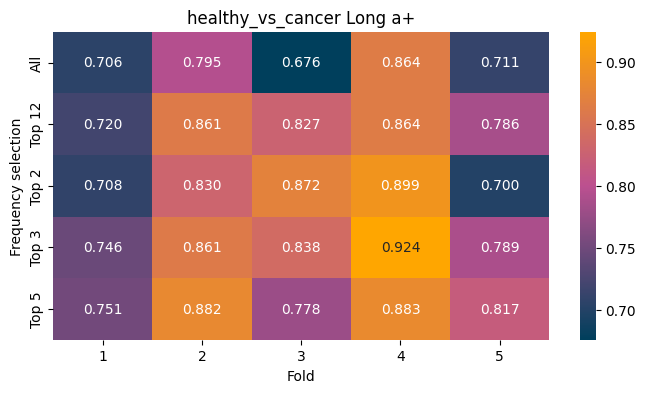

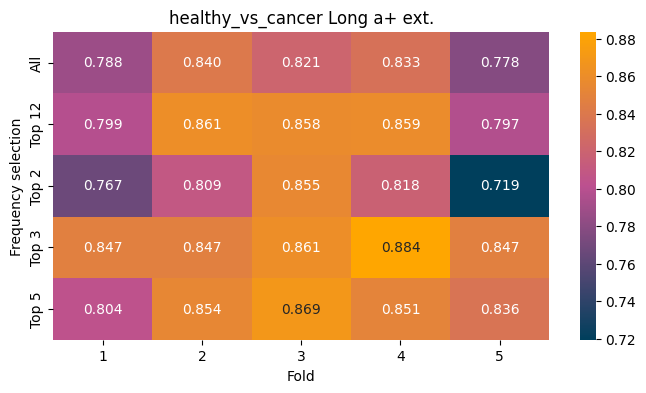

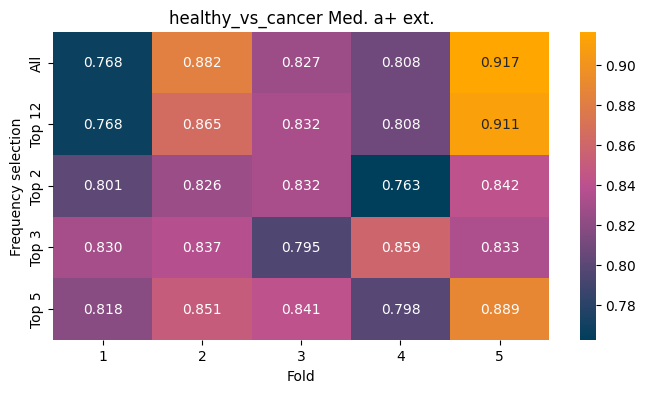

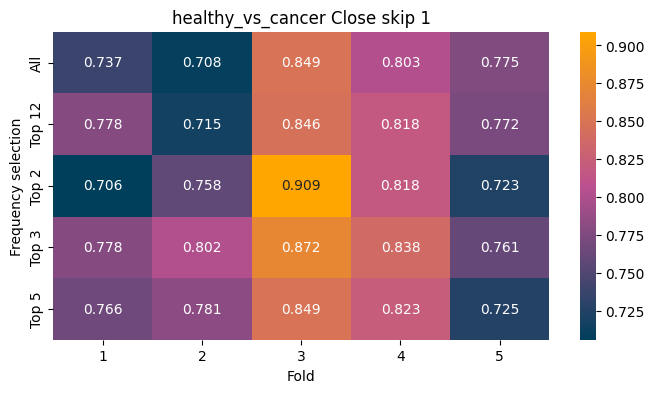

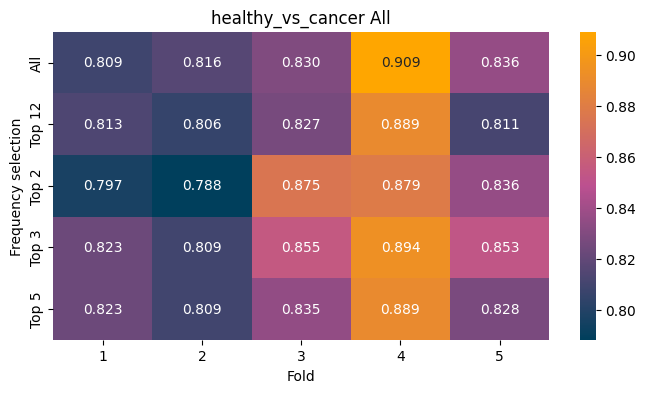

In [14]:
for mask_value in Mask_sel.keys():
    df_masked = df[df["Mask"] == mask_value]
    heatmap_data = df_masked.pivot(index="Fsel", columns="Fold", values="ROC_AUC_svm")

    plt.figure(figsize=(8, 4))
    sns.heatmap(heatmap_data, annot=True, cmap=cmap_gradient, fmt=".3f")
    plt.title(f"{class_task} {mask_value}")
    plt.ylabel("Frequency selection")
    plt.xlabel("Fold")
    plt.show()

In [15]:
Mask_sel

{'Long a+': 'vv_long_across',
 'Long a+ ext.': 'vv_long_across_extended',
 'Med. a+ ext.': 'vv_medium_across_extended',
 'Close skip 1': 'vv_distance_close_skip_1',
 'All': 'all'}

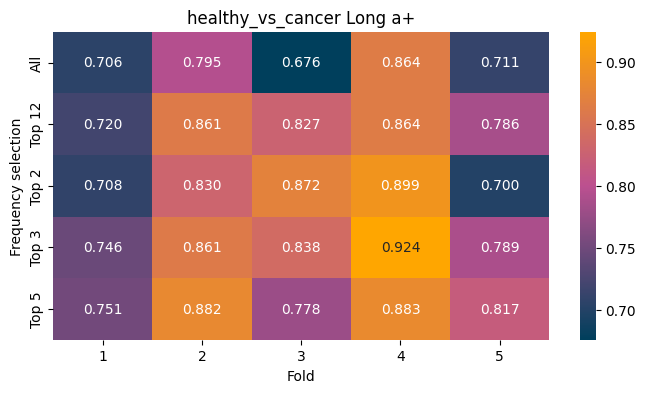

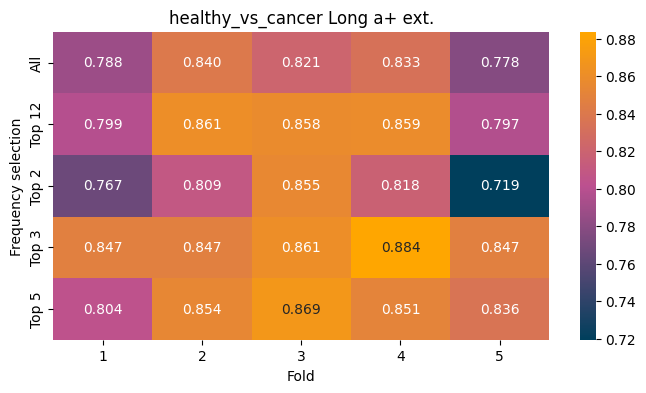

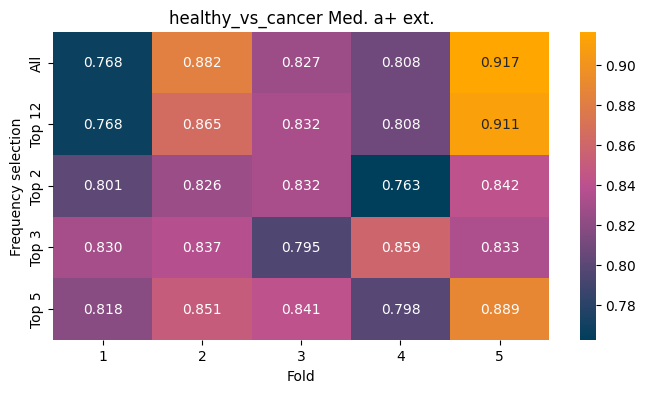

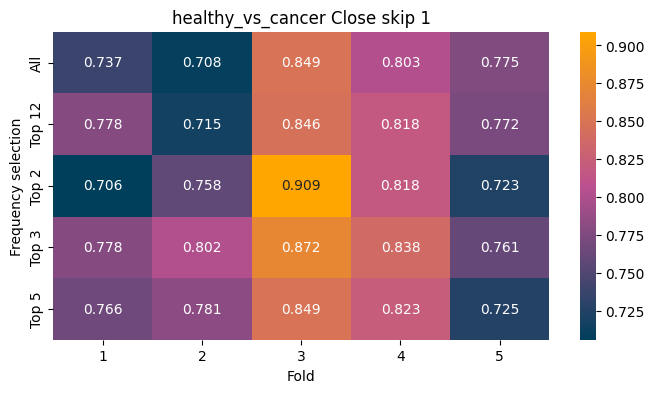

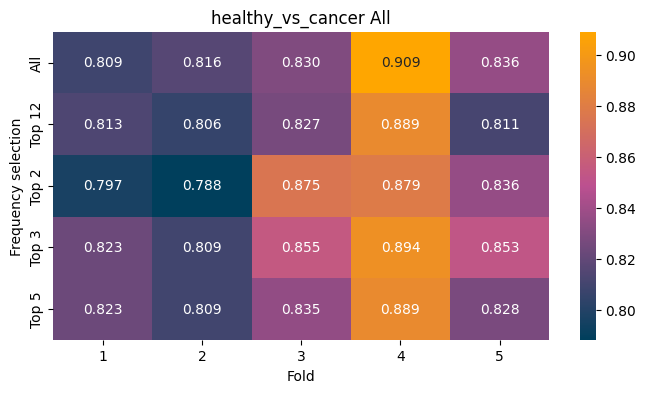

In [16]:
for mask_value in Mask_sel.keys():
    df_masked = df[df["Mask"] == mask_value]
    heatmap_data = df_masked.pivot(index="Fsel", columns="Fold", values="ROC_AUC_svm")

    plt.figure(figsize=(8, 4))
    sns.heatmap(heatmap_data, annot=True, cmap=cmap_gradient, fmt=".3f")
    plt.title(f"{class_task} {mask_value}")
    plt.ylabel("Frequency selection")
    plt.xlabel("Fold")
    plt.show()

In [17]:
df.head()

,Fold,Num params.,Mask,Fsel,ROC_AUC_svm
0,1,32,Long a+,Top 2,0.708134
1,1,48,Long a+,Top 3,0.746411
2,1,80,Long a+,Top 5,0.751196
3,1,192,Long a+,Top 12,0.720096
4,1,496,Long a+,All,0.705742


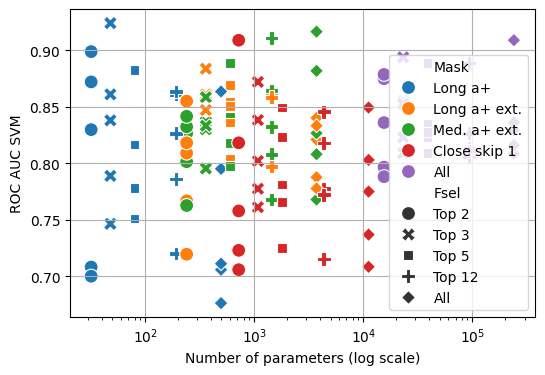

In [18]:
plt.figure(figsize=(6, 4))
sns.scatterplot(
    data=df, x="Num params.", y="ROC_AUC_svm", hue="Mask", style="Fsel", s=100
)
plt.xscale("log")
# plt.title("ROC_AUC_svm vs Num params. (log scale)")
plt.xlabel("Number of parameters (log scale)")
plt.ylabel("ROC AUC SVM")
plt.legend()
plt.grid(True)
plt.show()

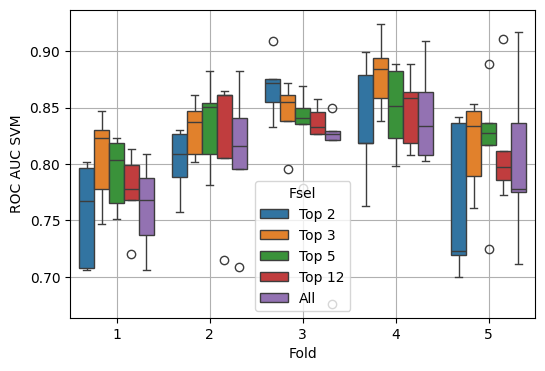

In [19]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="Fold", y="ROC_AUC_svm", hue="Fsel")
# plt.title("ROC AUC SVM by Frequency Selection (Fsel) grouped by Fold")
plt.xlabel("Fold")
plt.ylabel("ROC AUC SVM")
plt.grid(True)
plt.show()

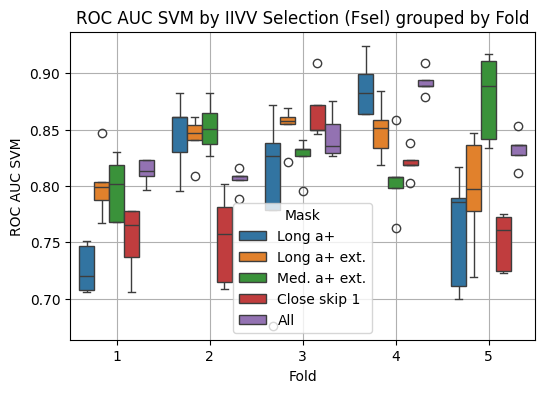

In [20]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="Fold", y="ROC_AUC_svm", hue="Mask")
plt.title("ROC AUC SVM by IIVV Selection (Fsel) grouped by Fold")
plt.xlabel("Fold")
plt.ylabel("ROC AUC SVM")
plt.grid(True)
plt.show()

In [21]:
print(df.groupby("Mask")["ROC_AUC_svm"].mean())
print(df.groupby("Fsel")["ROC_AUC_svm"].mean())
print(df.groupby("Fold")["ROC_AUC_svm"].mean())

Mask
All             0.837498
Close skip 1    0.788447
Long a+         0.803523
Long a+ ext.    0.828117
Med. a+ ext.    0.832037
Name: ROC_AUC_svm, dtype: float64
Fsel
All       0.803407
Top 12    0.819616
Top 2     0.805226
Top 3     0.835364
Top 5     0.826009
Name: ROC_AUC_svm, dtype: float64
Fold
1    0.777967
2    0.819757
3    0.837244
4    0.850960
5    0.803694
Name: ROC_AUC_svm, dtype: float64


In [22]:
df

,Fold,Num params.,Mask,Fsel,ROC_AUC_svm
0,1,32,Long a+,Top 2,0.708134
1,1,48,Long a+,Top 3,0.746411
2,1,80,Long a+,Top 5,0.751196
3,1,192,Long a+,Top 12,0.720096
4,1,496,Long a+,All,0.705742
...,...,...,...,...,...
120,5,15456,All,Top 2,0.836111
121,5,23184,All,Top 3,0.852778
122,5,38640,All,Top 5,0.827778
123,5,92736,All,Top 12,0.811111
